# Clasificación de imágenes de vocales manuscritas mediante aprendizaje supervisado

**Desarrollado e implementado por:**

- Izquierdo Camargo David Elías — Código: 2023214087
- Martínez Monsalvo Luis Jaime — Código: 2023214025
- Sierra Zapata Angelica — Código: 2023214030

**Curso:** Inteligencia Artificial  
**Docente:** PhD. Ing. Idanis Beatriz Díaz Bolaño  
**Universidad del Magdalena — 2026-II**



**Fuente del conjunto de datos:**  
[Handwriting Letter and Number Dataset — Kaggle](https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset)



# Documentación del problema

Nuestro problema se basa en el reconocimiento óptico de caracteres (OCR, por sus siglas en inglés), una tecnología de visión artificial que permite identificar y convertir caracteres presentes en imágenes en información comprensible para una computadora. En este proyecto se aborda específicamente la clasificación de vocales manuscritas, por lo que cada imagen debe asignarse a una de las cinco clases estudiadas.

## Enfoque y contextualización del problema: OCR aplicado a vocales

Se delimita el reconocimiento exclusivo a vocales (A, E, I, O, U), este proyecto aborda la unidad fundamental de la lectoescritura: el aislamiento y clasificación de caracteres discretos.

En lugar de procesar líneas o párrafos completos, el sistema se enfoca en resolver una tarea de clasificación de imágenes multiclase. El problema consiste en recibir una matriz de píxeles correspondiente a una única vocal y determinar con precisión a qué letra pertenece

## Fuentes consultadas

### Conjunto de datos

**Handwriting Letter and Number Dataset.** Conjunto de imágenes de caracteres manuscritos disponible en Kaggle. Para este proyecto se utilizan las imágenes seleccionadas para las cinco vocales.

[Consultar el conjunto de datos en Kaggle](https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset)

### Antecedente sobre reconocimiento de caracteres

Agrawal y colaboradores presentan una aplicación de reconocimiento óptico de caracteres mediante redes neuronales convolucionales. Su trabajo se toma como antecedente para comprender el reconocimiento de caracteres en imágenes; utiliza caracteres de inscripciones brahmi, distintos de las vocales estudiadas en este proyecto.

**Artículo:** *Optical Character Recognition using Convolutional Neural Networks for Ashokan Brahmi Inscriptions*.

[Consultar el artículo](https://arxiv.org/abs/2501.01981)

### Ética de la inteligencia artificial

La Recomendación sobre la Ética de la Inteligencia Artificial de la UNESCO se utilizó como referencia para analizar la privacidad, la equidad, la transparencia, la responsabilidad y la supervisión humana en una posible aplicación real del sistema.

[Consultar la Recomendación de la UNESCO](https://unesdoc.unesco.org/ark:/48223/pf0000381137_spa)

## Problemática encontrada

Al revisar los articulos sobre OCR, queda claro que el problema central no es solo hacer que una computadora lea, sino lograr que entienda imágenes del mundo real donde las letras nunca son perfectas. Los métodos viejos fallaban porque dependían de reglas muy rígidas, pero los documentos demuestran que usar aprendizaje supervisado (como las Redes Neuronales Convolucionales) es el camino correcto. Esto se debe a que estos modelos aprenden a identificar patrones por sí solos, superando problemas típicos como imágenes borrosas, sombras, cambios de luz o diferencias entre fuentes tipográficas y trazos hechos a mano.Llevando este problema al contexto de nuestro proyecto, nos enfocamos en una versión específica pero fundamental: el reconocimiento de vocales ($A, E, I, O, U$). En la práctica, el reto consiste en tomar una imagen con una sola vocal, pasarla por un proceso de limpieza para quitar el ruido, y lograr que nuestro modelo de Machine Learning analice esa cuadrícula de píxeles para adivinar con precisión de qué vocal se trata. Básicamente, le enseñamos a la máquina a diferenciar la forma única de cada vocal sin importar si está deformada, gruesa o escrita con estilos distintos

## Comprensión y estructura del dataset asignado


Cada observación corresponde a una imagen de un carácter manuscrito. La variable objetivo es la clase asignada a la imagen: 0, A, E, I o U. La etiqueta 0 representa la vocal O; se conserva ese identificador porque corresponde al nombre original de la clase en el dataset.

Después del preprocesamiento, cada imagen de 32 × 32 píxeles contiene 1.024 intensidades normalizadas entre 0 y 1. Random Forest, el MLP y Softmax utilizan los componentes principales obtenidos mediante PCA. El árbol de decisión seleccionado utiliza directamente los 1.024 píxeles aplanados, mientras que la CNN recibe la cuadrícula de 32 × 32 con un canal para conservar la disposición espacial.

## Objetivo general

Desarrollar y comparar modelos de aprendizaje supervisado para clasificar imágenes de las cinco vocales (A, E, I, O y U), mediante la inspección y preparación del conjunto de datos, el ajuste de hiperparámetros y la evaluación de su desempeño, con el fin de identificar el modelo que obtiene los mejores resultados de clasificación.

# Carga y uso del dataset

### Imports

In [ ]:
import os
from pathlib import Path
from PIL import Image, UnidentifiedImageError
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import random
import numpy as np
from pathlib import Path
import numpy as np


### Imports usados para los modelos

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import time
from sklearn.tree import plot_tree
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.decomposition import PCA
import time


### Lectura del dataset

In [ ]:
from urllib.request import urlretrieve
from zipfile import ZipFile

# Cuando exista un ZIP público autorizado, pega aquí su URL directa de descarga.
URL_DATASET = ""

RUTA_TRABAJO = Path("/content/ocr_vocales")
RUTA_SALIDAS = RUTA_TRABAJO / "salidas"
RUTA_SALIDAS.mkdir(parents=True, exist_ok=True)
RUTA_NPZ_32 = RUTA_SALIDAS / "DATASET_PROCESADO_32x32.npz"
RUTA_MODELOS = RUTA_SALIDAS / "MODELS"

CLASES_ESPERADAS = {"0": 1030, "A": 1010, "E": 1010, "I": 1010, "U": 1010}
EXTENSIONES_IMAGEN = {".jpg", ".jpeg", ".png"}
SEMILLA = 42
random.seed(SEMILLA)

carpeta_extraida = RUTA_TRABAJO / "datos"
if not carpeta_extraida.exists():
    archivo_zip = Path("/content/DATASET.zip")
    if not archivo_zip.is_file():
        if not URL_DATASET:
            raise FileNotFoundError(
                "Sube DATASET.zip al panel Archivos de Colab o configura URL_DATASET."
            )
        archivo_zip = RUTA_TRABAJO / "DATASET.zip"
        urlretrieve(URL_DATASET, archivo_zip)

    with ZipFile(archivo_zip) as archivo:
        archivo.extractall(carpeta_extraida)

RUTA_DATASET = (
    carpeta_extraida / "DATASET"
    if (carpeta_extraida / "DATASET").is_dir()
    else carpeta_extraida
)
carpetas_clase = [RUTA_DATASET / clase for clase in CLASES_ESPERADAS]
conteos_originales = {
    carpeta.name: sum(
        archivo.is_file() and archivo.suffix.lower() in EXTENSIONES_IMAGEN
        for archivo in carpeta.glob("*")
    )
    for carpeta in carpetas_clase
}
if conteos_originales != CLASES_ESPERADAS:
    raise ValueError(f"El ZIP no coincide con el dataset esperado. Conteos: {conteos_originales}")

print(f"Imágenes encontradas: {sum(conteos_originales.values())}")
print("Imágenes por clase:", conteos_originales)

Imágenes encontradas: 5070
Imágenes por clase: {'0': 1030, 'A': 1010, 'E': 1010, 'I': 1010, 'U': 1010}


# Visualización exploratoria apropiada al tipo de datos.

Se contará cuántos archivos de imagen hay en cada carpeta y se calculará el total del dataset. Los archivos que no tengan una extensión de imagen reconocida se registrarán por separado.


In [ ]:
conteos = {}
archivos_por_clase = {}
archivos_no_imagen = []
resumen_carpetas = []

for carpeta in carpetas_clase:
    archivos = [p for p in carpeta.rglob("*") if p.is_file()]
    imagenes = sorted(p for p in archivos if p.suffix.lower() in EXTENSIONES_IMAGEN)
    archivos_por_clase[carpeta.name] = imagenes
    conteos[carpeta.name] = len(imagenes)
    otros = [p for p in archivos if p.suffix.lower() not in EXTENSIONES_IMAGEN]
    archivos_no_imagen.extend(otros)
    resumen_carpetas.append({
        "Carpeta/clase": carpeta.name,
        "Archivos de imagen": len(imagenes),
        "Otros archivos": len(otros)
    })

df_carpetas = pd.DataFrame(resumen_carpetas)
display(df_carpetas)
print("Total de imágenes:", sum(conteos.values()))
print("Archivos que no son imágenes reconocidas:", len(archivos_no_imagen))

,Carpeta/clase,Archivos de imagen,Otros archivos
0,0,1030,0
1,A,1010,0
2,E,1010,0
3,I,1010,0
4,U,1010,0


Total de imágenes: 5070
Archivos que no son imágenes reconocidas: 0


## Distribución de imágenes por clase


El diagrama de barras permite comparar el número de imágenes disponibles en cada carpeta y observar si existen diferencias importantes en la representación de las clases.

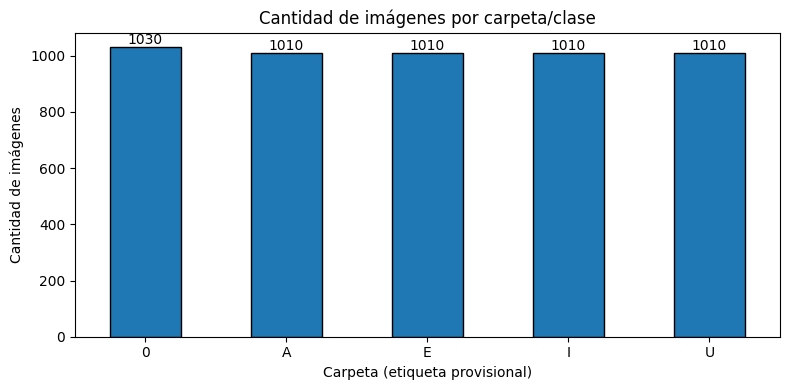

Diferencia entre la clase con más imágenes y la clase con menos imágenes: 20


In [ ]:
serie_conteos = pd.Series(conteos).sort_index()
ax = serie_conteos.plot(kind="bar", figsize=(8, 4), edgecolor="black")
ax.set_title("Cantidad de imágenes por carpeta/clase")
ax.set_xlabel("Carpeta (etiqueta provisional)")
ax.set_ylabel("Cantidad de imágenes")
ax.bar_label(ax.containers[0], fmt="%d")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if not serie_conteos.empty:
    print("Diferencia entre la clase con más imágenes y la clase con menos imágenes:",
          int(serie_conteos.max() - serie_conteos.min()))

## Visualización aleatoria

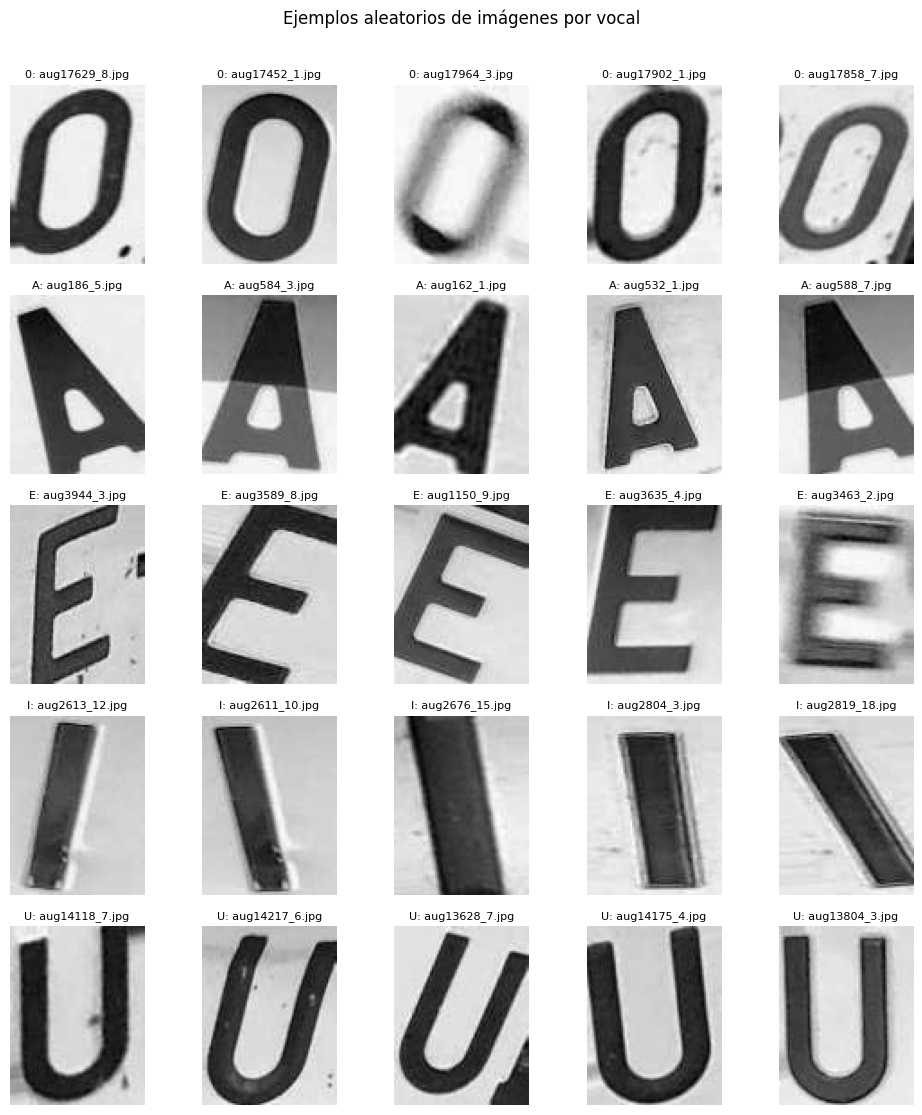

In [ ]:
# Cantidad de imágenes aleatorias por vocal
MUESTRAS_POR_VOCAL = 5

random.seed(42)
# Cada subcarpeta representa una vocal
carpetas = sorted(
    [carpeta for carpeta in RUTA_DATASET.iterdir() if carpeta.is_dir()],
    key=lambda carpeta: carpeta.name
)
imagenes_por_vocal = {}

for carpeta in carpetas:
    imagenes = [
        archivo for archivo in carpeta.iterdir()
        if archivo.is_file() and archivo.suffix.lower() in EXTENSIONES_IMAGEN
    ]
    imagenes_por_vocal[carpeta.name] = sorted(imagenes)
vocales = list(imagenes_por_vocal.keys())
cantidades = [len(imagenes_por_vocal[vocal]) for vocal in vocales]
    # 2. Cuadrícula con ejemplos aleatorios de cada vocal
filas = len(vocales)
columnas = MUESTRAS_POR_VOCAL

fig, ejes = plt.subplots(
    filas, columnas,
    figsize=(columnas * 2, filas * 2.2),
    squeeze=False
)
fig.suptitle("Ejemplos aleatorios de imágenes por vocal", y=1.01)
for fila, vocal in enumerate(vocales):
    disponibles = imagenes_por_vocal[vocal]
    seleccionadas = random.sample(
        disponibles, min(MUESTRAS_POR_VOCAL, len(disponibles))
    )

    for columna in range(columnas):
        eje = ejes[fila][columna]
        eje.axis("off")

        if columna < len(seleccionadas):
            ruta_imagen = seleccionadas[columna]
            try:
                with Image.open(ruta_imagen) as imagen:
                    eje.imshow(imagen.copy(), cmap="gray")
                eje.set_title(f"{vocal}: {ruta_imagen.name}", fontsize=8)
            except Exception:
                eje.set_title("No se pudo leer", fontsize=8)

plt.tight_layout()
plt.show()

## Identificación de inconsistencias y calidad de los datos

In [ ]:
import hashlib

print("=== REVISIÓN DE CALIDAD DE DATOS ===")

total_imagenes = 0
archivos_vacios = 0
imagenes_corruptas = 0
duplicados = 0
conteo_clases = {}
hashes_archivos = set()

if not RUTA_DATASET.exists():
    print(f"[ERROR] La ruta '{RUTA_DATASET}' no existe.")
else:
    clases = sorted(
        [carpeta for carpeta in RUTA_DATASET.iterdir() if carpeta.is_dir()],
        key=lambda carpeta: carpeta.name,
    )

    for clase_dir in clases:
        imagenes_clase = [
            archivo
            for archivo in clase_dir.iterdir()
            if archivo.is_file()
            and archivo.suffix.lower() in EXTENSIONES_IMAGEN
        ]

        conteo_clases[clase_dir.name] = len(imagenes_clase)
        total_imagenes += len(imagenes_clase)

        for ruta_img in imagenes_clase:
            if ruta_img.stat().st_size == 0:
                archivos_vacios += 1
                continue

            try:
                with Image.open(ruta_img) as imagen:
                    imagen.verify()

                hash_archivo = hashlib.sha256(
                    ruta_img.read_bytes()
                ).hexdigest()

                if hash_archivo in hashes_archivos:
                    duplicados += 1
                else:
                    hashes_archivos.add(hash_archivo)

            except (UnidentifiedImageError, OSError):
                imagenes_corruptas += 1

    print(f"\n[1] Total de imágenes evaluadas: {total_imagenes}")
    print(f"[2] Archivos vacíos: {archivos_vacios}")
    print(f"[3] Imágenes corruptas o inválidas: {imagenes_corruptas}")
    print(f"[4] Archivos duplicados por contenido: {duplicados}")

    print("\n[5] Distribución de imágenes por clase:")
    for clase, cantidad in sorted(conteo_clases.items()):
        porcentaje = 100 * cantidad / total_imagenes
        print(f"   - Clase '{clase}': {cantidad} imágenes ({porcentaje:.2f} %)")

    if conteo_clases:
        menor_conteo = min(conteo_clases.values())
        mayor_conteo = max(conteo_clases.values())

        if mayor_conteo > 1.5 * menor_conteo:
            print("\n[ALERTA] Se detectó un desbalance importante entre clases.")
        else:
            print("\n[OK] Las clases se encuentran razonablemente equilibradas.")

=== REVISIÓN DE CALIDAD DE DATOS ===

[1] Total general de imágenes evaluadas: 5070
[2] Valores faltantes o archivos vacíos: 0 detectados.
[3] Imágenes corruptas o inválidas: 0
[4] Posibles archivos duplicados: 0

[5] Distribución de muestras por clase (Categorías poco representadas):
   - Clase '0': 1030 imágenes (20.32%)
   - Clase 'A': 1010 imágenes (19.92%)
   - Clase 'E': 1010 imágenes (19.92%)
   - Clase 'I': 1010 imágenes (19.92%)
   - Clase 'U': 1010 imágenes (19.92%)

[OK]: Las clases se encuentran razonablemente equilibradas.


## Verificación de dimensiones, canales y visualización

In [ ]:

# Buscar el primer archivo de imagen dentro de las subcarpetas del dataset
archivos_imagen = list(RUTA_DATASET.glob("*/*.*"))
if not archivos_imagen:
  print(f"[ERROR] No se encontraron imágenes en la ruta '{RUTA_DATASET}'")
else:
  # Tomar la primera imagen disponible como muestra
  ruta_ejemplo = archivos_imagen[0]

  # 1. Uso de Pillow (Image.open, size, mode)
  img_pil = Image.open(ruta_ejemplo)
  print("--- PROPIEDADES CON PILLOW ---")
  print(f"Ruta del archivo: {ruta_ejemplo}")
  print(f"Tamaño (Dimensiones Ancho x Alto): {img_pil.size}")
  print(f"Modo (Canales/Formato): {img_pil.mode}")  # 'L' indica escala de grises

  # 2. Conversión a arreglo y verificación de formas (Canales y Dimensiones)
  img_array = np.array(img_pil)
  print("\n--- FORMA DEL ARREGLO (NUMPY) ---")
  print(f"Forma (Shape) del arreglo: {img_array.shape}")
  if len(img_array.shape) == 2:
    print("La imagen está en escala de grises (2 dimensiones: Alto x Ancho).")
  elif len(img_array.shape) == 3:
    print(
        "La imagen es a color (3 dimensiones: Alto x Ancho x Canales RGB/RGBA)."
    )

  # 3. Visualización con Matplotlib (plt.imshow)
  plt.figure(figsize=(5, 2))
  plt.imshow(img_array, cmap="gray" if len(img_array.shape) == 2 else None)
  plt.title(f"Ejemplo de vocal - Clase: {ruta_ejemplo.parent.name}")
  plt.axis("off")
  plt.show()

## Resumen del dataset

In [ ]:
print("\nRESUMEN DEL DATASET")
print(f"Carpetas/clases encontradas: {len(carpetas)}")
print(f"Total de imágenes: {sum(cantidades)}")

for vocal, rutas in imagenes_por_vocal.items():
    dimensiones = {}
    modos = {}
    ilegibles = []

    for ruta in rutas:
        try:
            with Image.open(ruta) as imagen:
                dimensiones[imagen.size] = dimensiones.get(imagen.size, 0) + 1
                modos[imagen.mode] = modos.get(imagen.mode, 0) + 1
                imagen.verify()
        except Exception:
            ilegibles.append(ruta.name)

    print(f"\nCarpeta {vocal}: {len(rutas)} imagenes")
    print(f"  Dimensiones (ancho, alto): {dimensiones}")
    print(f"  Modos de imagen: {modos}")
    print(f"  Archivos ilegibles: {len(ilegibles)}")
    if ilegibles:
        print(f"  Ejemplos de archivos ilegibles: {ilegibles[:5]}")

# Tratamiento de datos en etapas posteriores

A partir de la inspección realizada, se identificó que las imágenes tienen un tamaño de 75 × 100 píxeles y se encuentran en escala de grises. Para preparar los datos utilizados en los modelos, se aplican las siguientes operaciones:

1. **Escala de grises:** aunque las imágenes revisadas ya se encuentran en este modo, durante el procesamiento se utiliza la conversión a modo `L` para mantener una representación de un canal.

2. **Redimensionamiento:** las imágenes se transforman primero a 75 × 75 píxeles y posteriormente a 32 × 32 píxeles. La reducción permite utilizar menos valores de entrada por imagen, aunque puede modificar sus proporciones y reducir algunos detalles.

3. **Conversión y normalización:** las imágenes se representan mediante arreglos numéricos y sus valores de intensidad se dividen entre 255 para trabajar en el intervalo de 0 a 1.


# Reducción de resolución

Durante la exploración inicial, se identificó que las imágenes poseen variaciones espaciales nativas (con dimensiones originales de $75 \times 100$ píxeles). Para preparar los datos de cara a los algoritmos de aprendizaje automático, esta etapa ejecuta un pipeline de transformación con los siguientes fundamentos técnicos:Estandarización Cuadrada ($75 \times 75$): Se redimensionan las matrices espaciales a un formato uniforme de $75 \times 75$ píxeles. Esto simplifica la estructura de entrada de los datos, permitiendo que cualquier arquitectura de Machine Learning o Red Neuronal procese muestras homogéneas.

Técnica de Interpolación (Lanczos): Para el proceso de redimensionamiento (downscaling), se emplea el algoritmo de interpolación de alta calidad Lanczos (Image.Resampling.LANCZOS). Este método previene efectos de aliasing (dientes de sierra) y preserva de manera óptima los trazos continuos, bordes y la geometría esencial de cada vocal.   Normalización de Píxeles: Los valores de intensidad de los píxeles (originalmente en el rango de $0$ a $255$) son divididos por $255.0$ para escalarlos al intervalo continuo $[0.0, 1.0]$. Esta práctica es indispensable en modelos de Machine Learning para evitar sesgos numéricos debidos a magnitudes grandes y estabilizar la convergencia de los gradientes durante el entrenamiento.

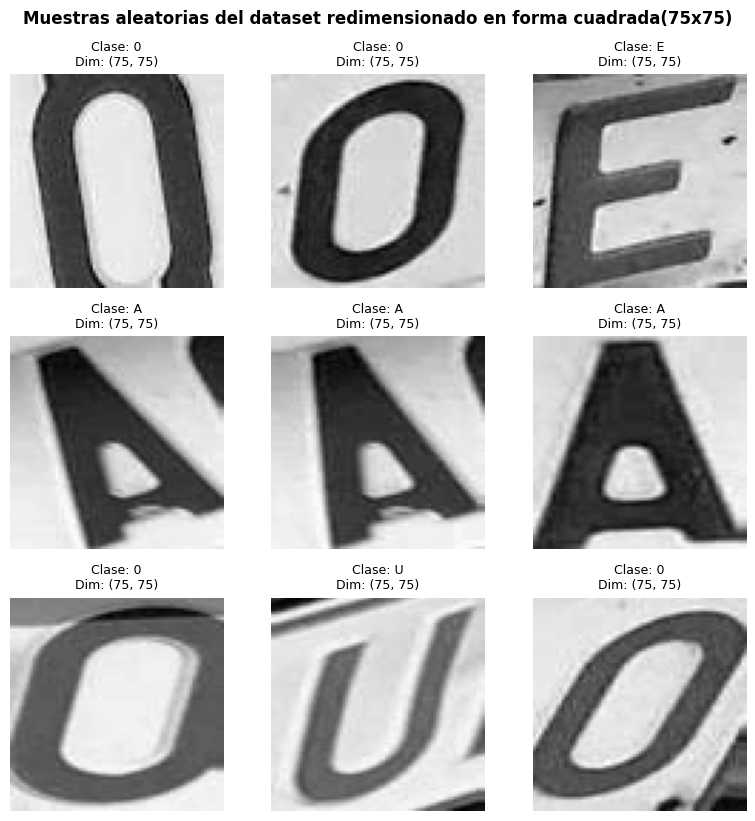

In [ ]:
NUEVO_TAMANO_75 = (75, 75)
X_procesado_75 = []
y_etiquetas_75 = []

clases = list(CLASES_ESPERADAS)

for clase in clases:
  ruta_clase = RUTA_DATASET / clase
  if not ruta_clase.is_dir():
    continue
  imagenes = [
      f
      for f in ruta_clase.iterdir()
      if f.is_file() and f.suffix.lower() in [".png", ".jpg", ".jpeg"]
  ]

  for ruta_img in imagenes:
    try:
      with Image.open(ruta_img) as img:
        img_gris = img.convert("L")
        img_redimensionada = img_gris.resize(
            NUEVO_TAMANO_75, Image.Resampling.LANCZOS
        )
        matriz = np.array(img_redimensionada, dtype=np.float32) / 255.0
        X_procesado_75.append(matriz)
        y_etiquetas_75.append(clase)
    except Exception as e:
      print(f"Error procesando {ruta_img}: {e}")

X_procesado_75 = np.array(X_procesado_75)
y_etiquetas_75 = np.array(y_etiquetas_75)

# Visualización exploratoria a 75x75
num_muestras = min(9, len(X_procesado_75))
indices_aleatorios = random.sample(range(len(X_procesado_75)), num_muestras)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))
axes = axes.flatten()

for i, idx in enumerate(indices_aleatorios):
  axes[i].imshow(X_procesado_75[idx], cmap="gray")
  axes[i].set_title(
      f"Clase: {y_etiquetas_75[idx]}\nDim: {X_procesado_75[idx].shape}",
      fontsize=9,
  )
  axes[i].axis("off")

plt.tight_layout()
plt.suptitle(
    "Muestras aleatorias del dataset redimensionado en forma cuadrada(75x75)",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
plt.show()

Una vez aplicado el filtro de escala de grises, la interpolación geométrica y la normalización, es una buena práctica de ingeniería de datos auditar visualmente una muestra aleatoria del dataset resultante. La siguiente visualización en cuadrícula permite comprobar que las vocales retienen sus características morfológicas esenciales y su legibilidad a pesar de la reducción espacial, mitigando posibles distorsiones excesivas antes de alimentar a los modelos de clasificación.

### Optimización y persistencia

Las imágenes en escala de grises se redimensionaron de 75 × 75 a 32 × 32 píxeles para reducir el tamaño de la entrada de los modelos. Con este cambio, cada imagen pasó de 5.625 a 1.024 valores de píxel. Las imágenes redimensionadas se guardaron junto con sus etiquetas en un archivo .npz. En la siguiente sección se muestran algunos ejemplos para observar cómo se ven los caracteres a la nueva resolución.

In [ ]:
NUEVO_TAMANO_32 = (32, 32)
X_procesado_opt = []

print("Reduciendo resolución espacial a 32x32 para optimizar el entrenamiento...")
for matriz in X_procesado_75:
  img_uint8 = (matriz * 255).astype(np.uint8)
  img_pil = Image.fromarray(img_uint8)
  img_redimensionada = img_pil.resize(
      NUEVO_TAMANO_32, Image.Resampling.LANCZOS
  )
  matriz_opt = np.array(img_redimensionada, dtype=np.float32) / 255.0
  X_procesado_opt.append(matriz_opt)

X_procesado_opt = np.array(X_procesado_opt)

# Guardar la versión optimizada a 32x32 en el entorno de Colab
RUTA_SALIDA_NPZ = RUTA_NPZ_32
np.savez_compressed(
    RUTA_SALIDA_NPZ, X=X_procesado_opt, y=y_etiquetas_75
)
print(f"Dataset optimizado 32x32 guardado correctamente en: {RUTA_SALIDA_NPZ}")

RUTA_SALIDA_CARPETA = RUTA_SALIDAS / "DATASET_PROCESADO_32x32"
RUTA_SALIDA_CARPETA.mkdir(parents=True, exist_ok=True)

for i, (matriz, clase) in enumerate(zip(X_procesado_opt, y_etiquetas_75)):
  ruta_clase_salida = RUTA_SALIDA_CARPETA / str(clase)
  ruta_clase_salida.mkdir(parents=True, exist_ok=True)
  img_uint8 = (matriz * 255).astype(np.uint8)
  img_pil_salida = Image.fromarray(img_uint8)
  ruta_archivo_salida = ruta_clase_salida / f"img_proc_32_{i}.png"
  img_pil_salida.save(ruta_archivo_salida)

print(
    "Todas las imágenes optimizadas a 32 × 32 se guardaron "
    "correctamente en el entorno de Colab."
)

Reduciendo resolución espacial a 32x32 para optimizar el entrenamiento...
Dataset optimizado 32x32 guardado correctamente en: /content/ocr_vocales/salidas/DATASET_PROCESADO_32x32.npz
¡Todas las imágenes optimizadas a 32x32 fueron guardadas exitosamente en Drive!


### Muestra exploratoria del dataset redimensionado

Dataset 32x32 cargado exitosamente. Forma de X: (5070, 32, 32), y: (5070,)


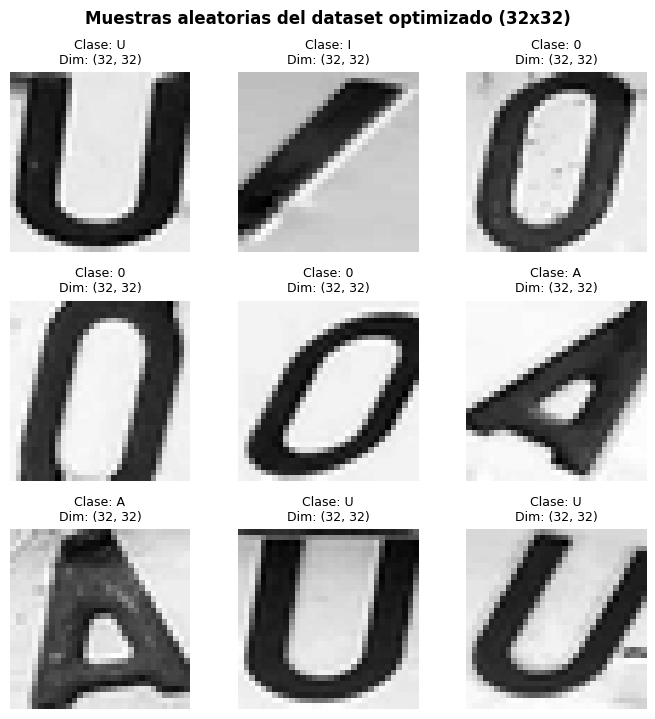

In [ ]:
# 1. Cargar el dataset optimizado a 32x32 desde el entorno de Colab
ruta_npz_32 = RUTA_NPZ_32

if ruta_npz_32.exists():
  data_opt = np.load(ruta_npz_32, allow_pickle=True)
  X_opt = data_opt["X"]
  y_opt = data_opt["y"]

  print(
      f"Dataset 32x32 cargado exitosamente. Forma de X: {X_opt.shape}, y:"
      f" {y_opt.shape}"
  )

  # 2. Seleccionar 9 índices aleatorios de forma segura
  num_muestras = min(9, len(X_opt))
  indices_aleatorios = random.sample(range(len(X_opt)), num_muestras)

  # 3. Configurar la cuadrícula de visualización en escala de grises
  fig, axes = plt.subplots(3, 3, figsize=(7, 7))
  axes = axes.flatten()

  for i, idx in enumerate(indices_aleatorios):
    imagen_matriz = X_opt[idx]
    etiqueta = y_opt[idx]

    axes[i].imshow(imagen_matriz, cmap="gray")
    axes[i].set_title(
        f"Clase: {etiqueta}\nDim: {imagen_matriz.shape}", fontsize=9
    )
    axes[i].axis("off")

  plt.tight_layout()
  plt.suptitle(
      "Muestras aleatorias del dataset optimizado (32x32)",
      fontsize=12,
      fontweight="bold",
      y=1.02,
  )
  plt.show()
else:
  print(
      f"[AVISO] No se encontró el archivo en {ruta_npz_32}. Verifica la ruta o"
      " asegúrate de haber ejecutado la celda de persistencia previa."
  )

### Histogramas de intensidad y contraste

Para complementar la inspección visual de las imágenes redimensionadas a 32 × 32 píxeles, calculamos dos medidas por imagen a partir de sus intensidades en escala de grises, normalizadas entre 0 y 1. La intensidad media es el promedio de los 1.024 píxeles y describe qué tan clara u oscura es la imagen en conjunto. El contraste global se aproxima mediante la desviación estándar de esas intensidades. Un valor mayor indica que en la imagen hay más variación entre tonos claros y oscuros.

Cada histograma agrupa los valores de una de estas medidas. El eje horizontal muestra el valor calculado por imagen y el eje vertical indica cuántas imágenes caen en cada intervalo. Ambas medidas se usan para describir el conjunto de datos durante la exploración.

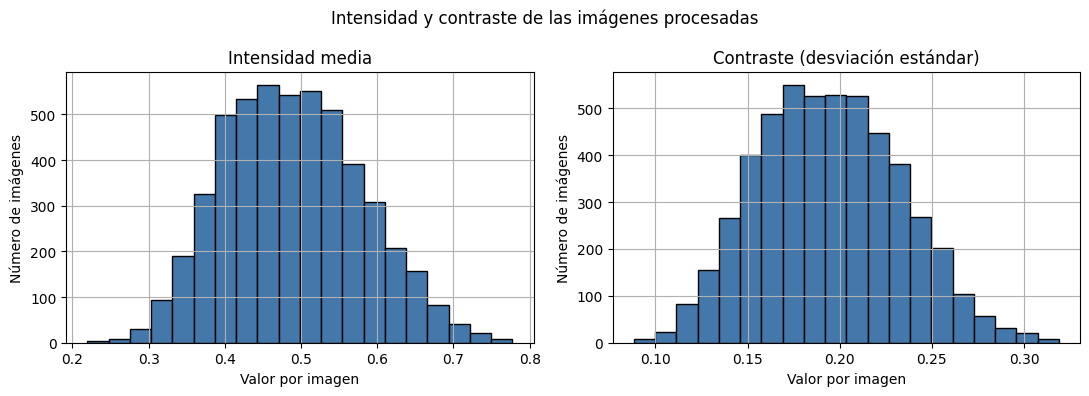

In [ ]:
with np.load(RUTA_NPZ_32) as datos_32:
    imagenes_32 = datos_32["X"]

pixeles_32 = imagenes_32.reshape(len(imagenes_32), -1)

resumen_imagenes = pd.DataFrame({
    "Intensidad media": pixeles_32.mean(axis=1),
    "Contraste (desviación estándar)": pixeles_32.std(axis=1),
})

ejes = resumen_imagenes.hist(
    layout=(1, 2),
    figsize=(11, 4),
    bins=20,
    color="#4477AA",
    edgecolor="black",
)

for ax in ejes.ravel():
    ax.set_xlabel("Valor por imagen")
    ax.set_ylabel("Número de imágenes")

plt.suptitle("Intensidad y contraste de las imágenes procesadas")
plt.tight_layout()
plt.show()

Interpretación de los histogramas

Las barras más altas de intensidad media se concentran aproximadamente entre 0,40 y 0,55, mientras que las de contraste global se concentran entre 0,16 y 0,23. En ambos histogramas hay menos imágenes hacia los extremos. Esto muestra que, incluso después de llevar todas las imágenes al mismo tamaño y rango de intensidad, persisten diferencias de luminosidad y de contraste entre ellas.

Como los histogramas reúnen todas las clases, describen la variación general del conjunto. Para saber si alguna de estas medidas difiere entre vocales, habría que examinar sus distribuciones por clase.

## Intensidad y contraste por vocal

Los histogramas anteriores muestran cómo se distribuyen la intensidad media y el contraste global al reunir todas las imágenes. Para examinar si estas medidas presentan diferencias entre vocales, se construye un diagrama de caja para cada medida. La línea dentro de cada caja indica la mediana y la caja abarca el 50 % central de los valores. Esto permite comparar el centro, la dispersión y el solapamiento de las distribuciones entre clases.

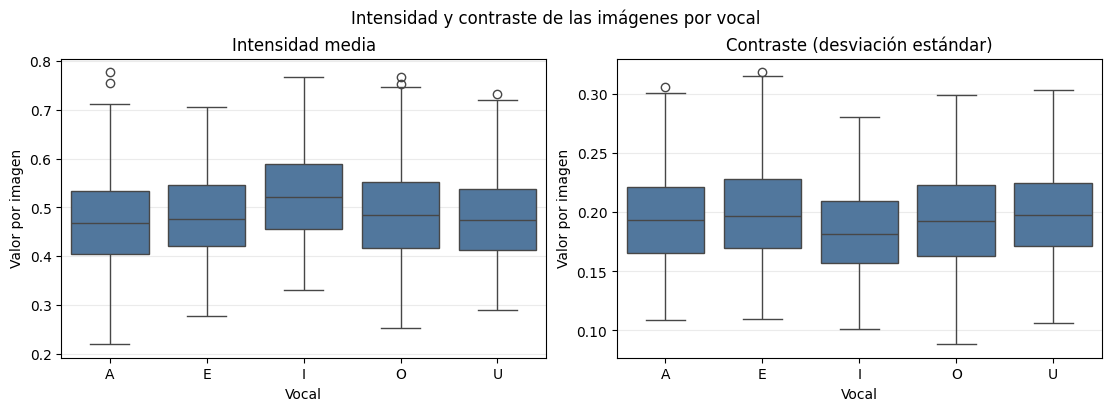

In [ ]:
import seaborn as sns

with np.load(RUTA_NPZ_32) as datos_32:
    etiquetas_32 = datos_32["y"].ravel()

resumen_por_vocal = resumen_imagenes.copy()
resumen_por_vocal["Vocal"] = (
    pd.Series(etiquetas_32).astype(str).replace({"0": "O"})
)

orden_vocales = ["A", "E", "I", "O", "U"]
medidas = ["Intensidad media", "Contraste (desviación estándar)"]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

for ax, medida in zip(ejes, medidas):
    sns.boxplot(
        data=resumen_por_vocal,
        x="Vocal",
        y=medida,
        order=orden_vocales,
        color="#4477AA",
        ax=ax,
    )
    ax.set_title(medida)
    ax.set_ylabel("Valor por imagen")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Intensidad y contraste de las imágenes por vocal")
plt.show()

Interpretación de los diagramas de caja

La vocal I presenta la mediana más alta de intensidad media, cercana a 0,52, y la mediana más baja de contraste global, cercana a 0,18. En este conjunto, sus imágenes tienden a ser más claras en promedio y a presentar menor variación entre las intensidades de sus píxeles. Las otras cuatro vocales muestran medianas más próximas entre sí en ambas medidas.

Las cajas de las cinco vocales se solapan en ambos gráficos. Esto indica que distintos caracteres pueden tener niveles similares de intensidad y contraste. Estas medidas ayudan a describir las imágenes, pero por sí solas ofrecen una separación limitada entre clases. Para reconocer las vocales también importa cómo se distribuyen los píxeles y qué forma dibujan.

## Justificación del redimensionamiento a 32 × 32 píxeles

Las imágenes en escala de grises se redimensionaron de 75 × 75 a 32 × 32 píxeles para reducir el tamaño de la entrada de los modelos. La elección de esta resolución se justifica a partir de dos aspectos.

1. **Reducción de dimensionalidad.** Cada imagen pasó de 5.625 a 1.024 valores de píxel, lo que representa una reducción del 81,8 %. Para los modelos que usan PCA, estos 1.024 valores se organizan en un vector sobre el que se aplica la reducción a componentes principales. La red neuronal convolucional (CNN) recibe la imagen como una cuadrícula de 32 × 32 píxeles con un solo canal.

2. **Legibilidad y pérdida de detalle.** En la muestra visualizada, las vocales siguen siendo reconocibles a 32 × 32 píxeles, aunque el redimensionamiento puede eliminar detalles finos de los trazos. Para determinar cómo influye este cambio en el desempeño o en el sobreajuste de los modelos, habría que comparar ambas resoluciones bajo el mismo protocolo de evaluación.

Las imágenes redimensionadas y sus etiquetas se guardaron en el archivo `DATASET_PROCESADO_32x32.npz`, que se utiliza como base para el entrenamiento y la evaluación de los modelos.

# Diseño de experimentos y entrenamiento de modelos

El experimento compara cinco modelos de clasificación supervisada para el reconocimiento de vocales a partir de imágenes de 32 × 32 píxeles.

1. **División de los datos.** Las 5.070 imágenes se dividieron en 4.056 para entrenamiento (80 %) y 1.014 para prueba (20 %). La división se hizo de forma estratificada, con semilla 42, para conservar aproximadamente la proporción de cada vocal en ambos conjuntos. Los cinco modelos usan la misma división.

2. **Representación de las imágenes**. Random Forest, el MLP y Softmax utilizan componentes principales obtenidos mediante PCA. El árbol de decisión seleccionado trabaja con los 1.024 píxeles aplanados sin PCA. La CNN utiliza directamente imágenes de 32 × 32 píxeles con un canal.
3. **Búsqueda de hiperparámetros y evaluación.** Las configuraciones incluidas en cada búsqueda con `GridSearchCV` se comparan mediante validación cruzada de cinco particiones sobre el conjunto de entrenamiento, usando la exactitud (*accuracy*) como criterio. El conjunto de prueba se utiliza para la evaluación final mediante la exactitud, el reporte de clasificación por vocal y la matriz de confusión.

In [ ]:
# 1. Cargar el dataset optimizado a 32x32 desde el entorno de Colab
ruta_npz_32 = RUTA_NPZ_32
data_opt = np.load(ruta_npz_32, allow_pickle=True)

X_opt = data_opt["X"]  # Forma esperada: (5070, 32, 32)
y_opt = data_opt["y"]  # Etiquetas de las vocales ('0', 'A', 'E', 'I', 'U')

print(f"Dimensiones cargadas - X: {X_opt.shape}, y: {y_opt.shape}")

# 2. Aplanar las imágenes de 32x32 a vectores unidimensionales de 1024 características
n_muestras = X_opt.shape[0]
X_flat = X_opt.reshape(n_muestras, -1)
print(f"Forma de la matriz aplanada (X_flat): {X_flat.shape}")

# 3. Codificar las etiquetas categóricas a valores numéricos enteros
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_opt)

# 4. División Train/Test estratificada (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"Conjunto de entrenamiento (X_train): {X_train.shape}")
print(f"Conjunto de prueba (X_test): {X_test.shape}")

Dimensiones cargadas - X: (5070, 32, 32), y: (5070,)
Forma de la matriz aplanada (X_flat): (5070, 1024)
Conjunto de entrenamiento (X_train): (4056, 1024)
Conjunto de prueba (X_test): (1014, 1024)


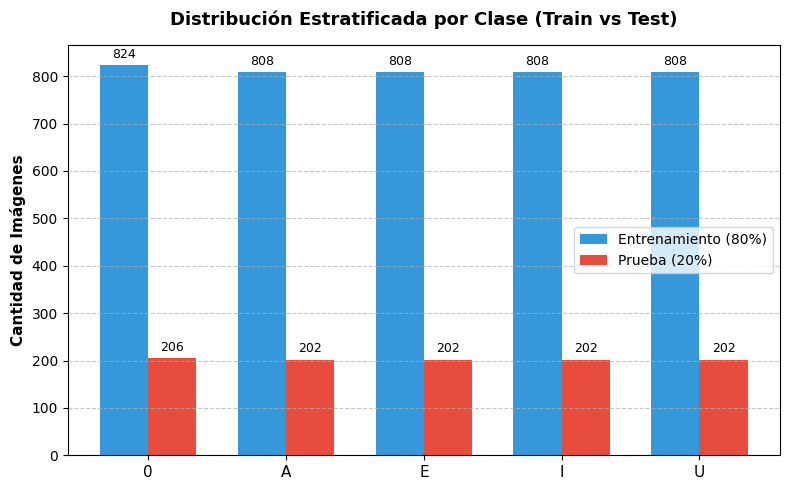

In [ ]:
# Contar la frecuencia de cada clase en y_train y y_test
clases_unicas = np.unique(y_encoded)
nombres_clases = label_encoder.classes_

conteo_train = [np.sum(y_train == c) for c in clases_unicas]
conteo_test = [np.sum(y_test == c) for c in clases_unicas]

# Configurar la gráfica de barras agrupadas
x = np.arange(len(nombres_clases))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(
    x - ancho/2, conteo_train, ancho, label='Entrenamiento (80%)', color='#3498db'
)
rects2 = ax.bar(
    x + ancho/2, conteo_test, ancho, label='Prueba (20%)', color='#e74c3c'
)

# Etiquetas y diseño académico
ax.set_ylabel('Cantidad de Imágenes', fontsize=11, fontweight='bold')
ax.set_title(
    'Distribución Estratificada por Clase (Train vs Test)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_xticks(x)
ax.set_xticklabels(nombres_clases, fontsize=11)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Mostrar valores exactos sobre las barras
def autolabel(rects):
  for rect in rects:
    height = rect.get_height()
    ax.annotate(
        f'{height}',
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 3),  # 3 points vertical offset
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=9,
    )

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

# División de datos y reducción de dimensionalidad (PCA)

Después de la división estratificada, se aplicó el análisis de componentes principales (PCA) a las imágenes aplanadas para reducir las 1.024 variables de píxel a un conjunto de componentes que conserva al menos el 95 % de la varianza del conjunto de entrenamiento. Esta representación se utiliza en la regresión logística multiclase, Random Forest y el perceptrón multicapa. En el árbol de decisión se evaluó inicialmente como referencia, pero la comparación posterior mediante validación cruzada seleccionó como modelo final el árbol entrenado con los 1.024 píxeles sin PCA.

El PCA se ajustó con las 4.056 imágenes de entrenamiento. Luego se utilizó esa misma transformación en las 1.014 imágenes de prueba. Así, el conjunto de prueba quedó fuera del ajuste del PCA.

**Alcance de la validación cruzada.** El PCA se ajustó una sola vez, antes de la búsqueda de hiperparámetros. Por eso, las imágenes de las particiones internas de validación también contribuyeron al cálculo de los componentes. Para evaluar el preprocesamiento y el modelo juntos dentro de cada partición, el PCA tendría que ajustarse dentro de la validación cruzada mediante un `Pipeline`.

In [ ]:
# ======================================================================
#                              APLICACIÓN DE PCA
# ======================================================================

print("--- Iniciando Reducción de Dimensionalidad con PCA ---")
inicio_pca = time.time()

# 1. Instanciamos el PCA para que retenga el 95% de la varianza explicada.
pca = PCA(n_components=0.95, random_state=42)

# 2. Ajustamos el PCA SOLO con los datos de entrenamiento (X_train)
# y transformamos AMBOS conjuntos (Train y Test)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test) # Al conjunto de datos de prueba solo lo transformamos, NO hacemos fit.


tiempo_fin_pca = time.time() - inicio_pca

print(f"PCA completado en {tiempo_fin_pca:.2f} segundos.")
print(f"Dimensiones de X_train ANTES de PCA: {X_train.shape[1]} características (pixeles)")
print(f"Dimensiones de X_train DESPUÉS de PCA: {X_train_pca.shape[1]} componentes principales")
print(f"Dimensiones de X_test DESPUÉS de PCA: {X_test_pca.shape[1]} componentes principales")
print(f"Varianza total explicada retenida: {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

# 4. Guardado de los archivos para las siguientes etapas
print("\n--- Guardando archivos para persistencia ---")
RUTA_MODELOS.mkdir(parents=True, exist_ok=True)

ruta_pca = RUTA_MODELOS / "pca_transform.pkl"
ruta_datos_pca = RUTA_MODELOS / "datos_transformados_pca.npz"

# Guardar el modelo PCA
joblib.dump(pca, ruta_pca)

# Guardar los arreglos transformados para que los modelos los consuman después
np.savez_compressed(
    ruta_datos_pca,
    X_train_pca=X_train_pca,
    X_test_pca=X_test_pca,
    y_train=y_train,
    y_test=y_test
)

print(f"Transformación PCA guardada en el entorno de Colab: {ruta_pca.name}")
print(f"Conjuntos de datos transformados guardados exitosamente en: {ruta_datos_pca.name}")

--- Iniciando Reducción de Dimensionalidad con PCA ---
PCA completado en 1.11 segundos.
Dimensiones de X_train ANTES de PCA: 1024 características (pixeles)
Dimensiones de X_train DESPUÉS de PCA: 94 componentes principales
Dimensiones de X_test DESPUÉS de PCA: 94 componentes principales
Varianza total explicada retenida: 95.05%

--- Guardando archivos para persistencia ---
Transformación PCA guardada en drive para entrenamientos posteriores: pca_transform.pkl
Conjuntos de datos transformados guardados exitosamente en: datos_transformados_pca.npz


# Random Forest

Random Forest combina las predicciones de varios árboles de decisión. En este experimento se compararon dos configuraciones sobre los componentes principales de las imágenes.

- **Bosque base.** Se entrenó con los hiperparámetros por defecto y la semilla 42.
- **Bosque ajustado.** Se evaluaron 162 configuraciones con `GridSearchCV`, variando el número de árboles, su profundidad máxima, el mínimo de muestras para dividir un nodo o formar una hoja y el número de variables consideradas en cada división.

La comparación se hizo mediante validación cruzada de cinco particiones, con la exactitud media como criterio de selección. El bosque base obtuvo la mayor exactitud media y se eligió para representar a Random Forest en la comparación de los cinco modelos. Los resultados en el conjunto de prueba se reportaron por separado.

## Random Forest base

In [ ]:
modelo_rf_base = RandomForestClassifier(random_state=42)
modelo_rf_base.fit(X_train_pca, y_train)

print("Random Forest base entrenado correctamente con los datos PCA.")

Random Forest base entrenado correctamente con los datos PCA.


## Bosque ajustado con GridSearchCV

### Configuración de la búsqueda de hiperparámetros




In [ ]:
# Malla ampliada incluyendo los hiperparámetros de la diapositiva de clase
param_grid_rf_completo = {
    'n_estimators': [50,100, 150],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2,5],
    'min_samples_leaf': [1, 2, 3],      # Mínimo de muestras por hoja
    'max_features': [2, 3, 4]           # Variables candidatas por división
}

rf_base = RandomForestClassifier(random_state=42)

# GridSearchCV con la nueva malla ampliada
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf_completo,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
print("Configuración de Random Forest y malla de hiperparámetros listas.")


Configuración de Random Forest y malla de hiperparámetros listas.


### Entrenamiento del bosque ajustado

In [ ]:
print("Iniciando entrenamiento con malla ampliada (sobre datos PCA)...")
inicio = time.time()

# Utilizamos los datos de entrenamiento transformados por PCA
grid_search_rf.fit(X_train_pca, y_train)

tiempo_fin = time.time() - inicio
print(f"¡Finalizado en {tiempo_fin:.2f} segundos!")
print(f"Mejores hiperparámetros: {grid_search_rf.best_params_}")
print(f"Mejor precisión (cv=5): {grid_search_rf.best_score_:.4f}")

# Extraer el mejor modelo para tenerlo listo
mejor_modelo_rf = grid_search_rf.best_estimator_

Iniciando entrenamiento con malla ampliada (sobre datos PCA)...
Fitting 5 folds for each of 162 candidates, totalling 810 fits
¡Finalizado en 458.31 segundos!
Mejores hiperparámetros: {'max_depth': 5, 'max_features': 4, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}
Mejor precisión (cv=5): 0.9862


### Resultados de la búsqueda de hiperparámetros

In [ ]:
resultados_malla_rf = pd.DataFrame(grid_search_rf.cv_results_)
mejores_configuraciones_rf = resultados_malla_rf.sort_values(
    "rank_test_score", kind="stable"
).head(10)

display(mejores_configuraciones_rf[[
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
    "param_max_features",
    "mean_test_score",
    "std_test_score",
]].rename(columns={
    "param_n_estimators": "Árboles",
    "param_max_depth": "Profundidad máxima",
    "param_min_samples_split": "Mínimo para dividir",
    "param_min_samples_leaf": "Mínimo por hoja",
    "param_max_features": "Variables por división",
    "mean_test_score": "Exactitud media",
    "std_test_score": "Desviación estándar",
}).style.format({
    "Exactitud media": "{:.2%}",
    "Desviación estándar": lambda valor: f"{valor * 100:.2f} pp",
}))

,Árboles,Profundidad máxima,Mínimo para dividir,Mínimo por hoja,Variables por división,Exactitud media,Desviación estándar
152,150,5,2,2,4,98.62%,0.18 pp
146,150,5,2,1,4,98.55%,0.25 pp
151,100,5,2,2,4,98.52%,0.23 pp
158,150,5,2,3,4,98.50%,0.14 pp
161,150,5,5,3,4,98.50%,0.14 pp
149,150,5,5,1,4,98.47%,0.22 pp
131,150,5,5,1,3,98.42%,0.65 pp
148,100,5,5,1,4,98.42%,0.16 pp
155,150,5,5,2,4,98.40%,0.21 pp
140,150,5,2,3,3,98.37%,0.46 pp


###	Visualización de un árbol del bosque ajustado



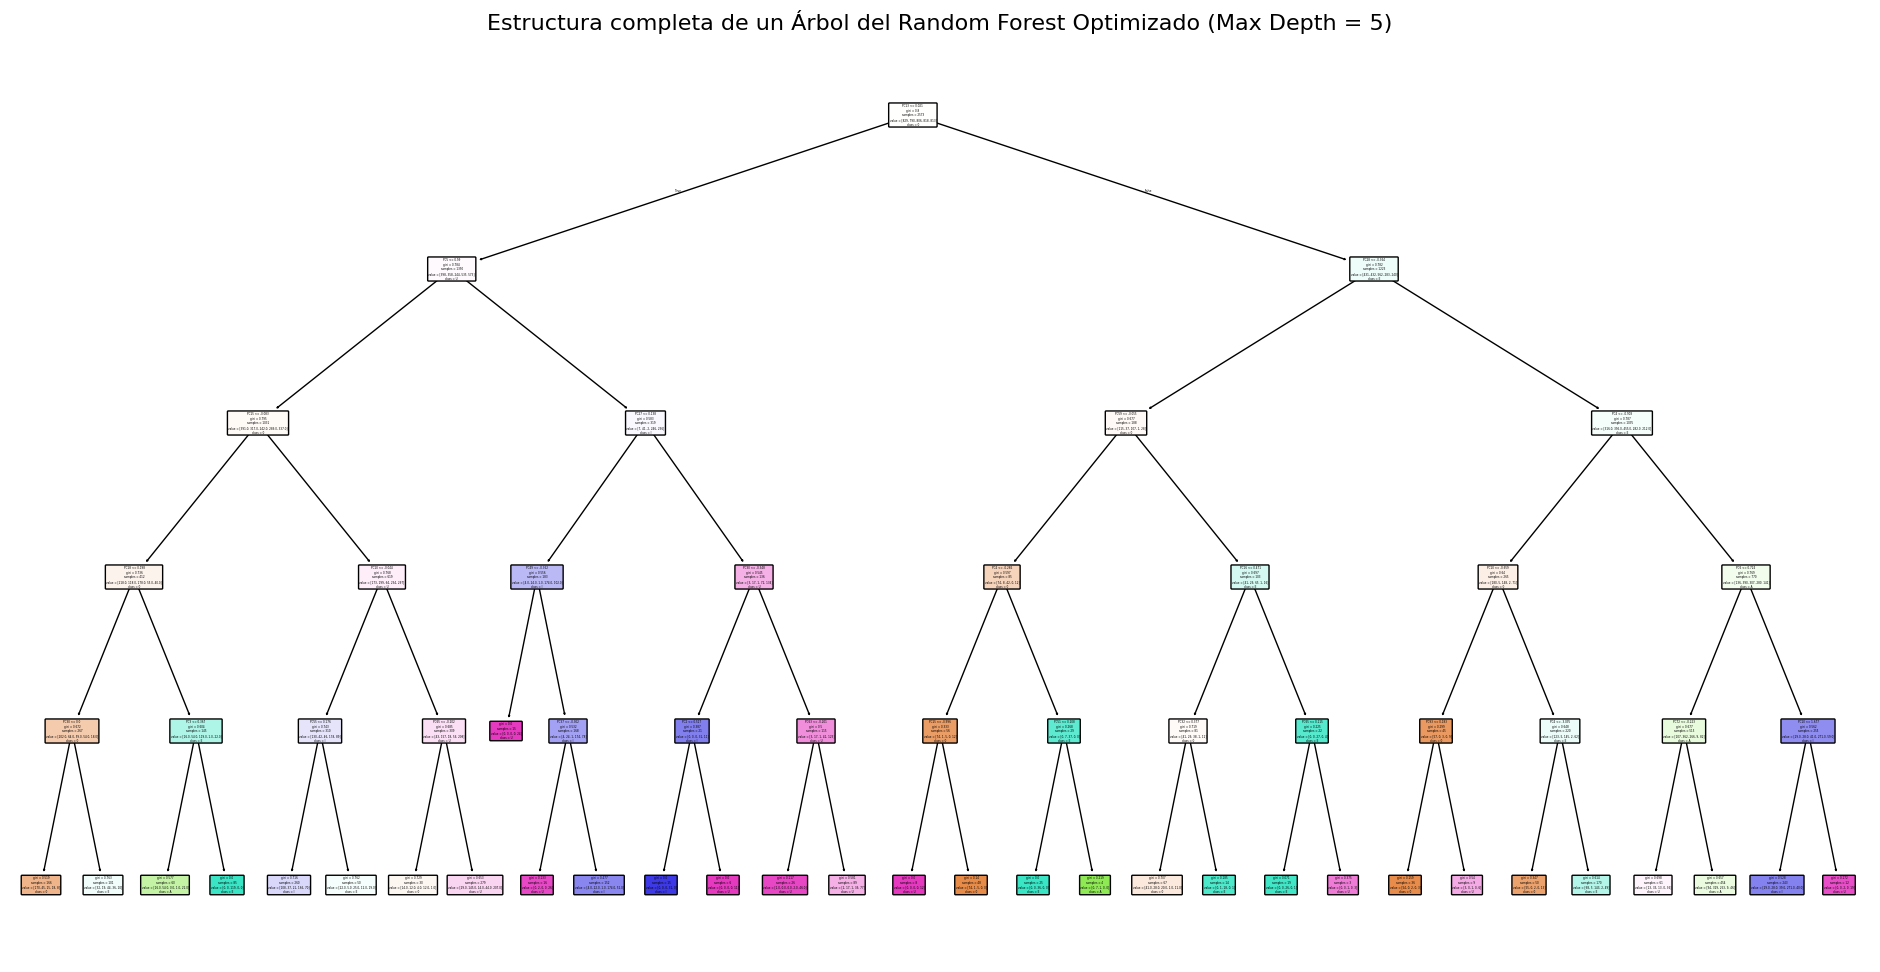

In [ ]:
# Extraemos el primer árbol del bosque optimizado
arbol_optimizado = mejor_modelo_rf.estimators_[0]

plt.figure(figsize=(24, 12))

plot_tree(
    arbol_optimizado,
    max_depth=5,                      # Como su profundidad máxima es 5, lo veremos completo
    filled=True,                      # Colores para distinguir las clases
    rounded=True,                     # Estética limpia
    feature_names=[f"PC{i + 1}" for i in range(X_train_pca.shape[1])],
    class_names=label_encoder.classes_
)

plt.title("Estructura completa de un Árbol del Random Forest Optimizado (Max Depth = 5)", fontsize=16)
plt.show()

## Comparación de la complejidad de los bosques

In [ ]:
complejidad_rf = []

for nombre, bosque in [
    ("Base (seleccionado)", modelo_rf_base),
    ("Ajustado con GridSearchCV", mejor_modelo_rf),
]:
    complejidad_rf.append({
        "Modelo": nombre,
        "Número de árboles": bosque.n_estimators,
        "Profundidad promedio": np.mean([
            arbol.get_depth() for arbol in bosque.estimators_
        ]),
        "Hojas promedio por árbol": np.mean([
            arbol.get_n_leaves() for arbol in bosque.estimators_
        ]),
    })

display(pd.DataFrame(complejidad_rf).round(2))

,Modelo,Número de árboles,Profundidad promedio,Hojas promedio por árbol
0,Base (seleccionado),100,17.38,323.15
1,Ajustado con GridSearchCV,150,5.00,29.45


El bosque base tiene 100 árboles, con una profundidad promedio de 17,38. El bosque ajustado tiene 150 árboles, pero cada uno es menos profundo y tiene muchas menos hojas en promedio. Aunque el ajustado contiene más árboles, sus árboles individuales son más simples. En esta corrida, esa reducción de complejidad por árbol vino acompañada de una menor exactitud media en validación cruzada.

## Comparación en validación cruzada

In [ ]:
from sklearn.model_selection import cross_val_score

puntajes_rf_base = cross_val_score(
    modelo_rf_base,
    X_train_pca,
    y_train,
    cv=grid_search_rf.cv,
    scoring=grid_search_rf.scoring,
    n_jobs=-1,
)

indice_rf = grid_search_rf.best_index_
resultados_cv_rf = grid_search_rf.cv_results_

tabla_rf_validacion = pd.DataFrame({
    "Modelo": ["Base", "Ajustado con GridSearchCV"],
    "Exactitud media": [
        puntajes_rf_base.mean(),
        resultados_cv_rf["mean_test_score"][indice_rf],
    ],
    "Desviación estándar (pp)": [
        puntajes_rf_base.std() * 100,
        resultados_cv_rf["std_test_score"][indice_rf] * 100,
    ],
})

display(tabla_rf_validacion.style.format({
    "Exactitud media": "{:.2%}",
    "Desviación estándar (pp)": "{:.2f}",
}))

,Modelo,Exactitud media,Desviación estándar (pp)
0,Base,99.75%,0.00
1,Ajustado con GridSearchCV,98.62%,0.18


## Comparación de Random Forest con y sin PCA

Después de seleccionar el bosque base frente al bosque ajustado, se analiza el efecto de la representación de las imágenes. Se compara el mismo Random Forest con sus hiperparámetros por defecto y semilla 42 utilizando dos entradas: los píxeles aplanados de las imágenes de 32 × 32 y los componentes obtenidos mediante PCA.

La comparación se realiza mediante las mismas cinco particiones de validación cruzada y usando únicamente el conjunto de entrenamiento. En la variante con PCA, la transformación se ajusta dentro de cada partición mediante un `Pipeline`, evitando que las imágenes de validación participen en el cálculo de los componentes. De esta manera, la única diferencia entre las dos variantes es la representación de entrada.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_validate
import time

cv_rf_representacion = StratifiedKFold(n_splits=5, shuffle=False)

variantes_rf = {
    "Con PCA": Pipeline([
        ("pca", PCA(n_components=0.95, random_state=42)),
        ("random_forest", RandomForestClassifier(random_state=42)),
    ]),
    "Sin PCA": RandomForestClassifier(random_state=42),
}

comparacion_pca_rf = []

for representacion, modelo in variantes_rf.items():
    inicio = time.time()

    resultados_cv = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv_rf_representacion,
        scoring="accuracy",
        n_jobs=-1,
        return_train_score=False,
    )

    comparacion_pca_rf.append({
        "Representación": representacion,
        "Exactitud media": resultados_cv["test_score"].mean(),
        "Desviación estándar (pp)": resultados_cv["test_score"].std() * 100,
        "Tiempo total (s)": time.time() - inicio,
    })

tabla_pca_rf = (
    pd.DataFrame(comparacion_pca_rf)
    .sort_values("Exactitud media", ascending=False, kind="stable")
    .reset_index(drop=True)
)

display(
    tabla_pca_rf.style.format({
        "Exactitud media": "{:.4%}",
        "Desviación estándar (pp)": "{:.3f}",
        "Tiempo total (s)": "{:.2f}",
    })
)

,Representación,Exactitud media,Desviación estándar (pp),Tiempo total (s)
0,Con PCA,99.7535%,0.078,28.83
1,Sin PCA,99.7041%,0.126,22.51


### Selección de la representación

Las dos representaciones alcanzaron resultados muy similares. Random Forest con PCA obtuvo una exactitud media de **99,7535 %** y una desviación estándar de **0,078 puntos porcentuales**, mientras que la versión sin PCA alcanzó **99,7041 %** y una desviación de **0,126 puntos porcentuales**.

La diferencia de aproximadamente **0,05 puntos porcentuales** es pequeña, por lo que no se interpreta como una mejora amplia. Sin embargo, como la exactitud media es el criterio principal de selección y la variante con PCA también presentó menor variación entre particiones, se conserva **Random Forest con PCA**. La versión sin PCA completó la validación en menos tiempo, pero obtuvo una exactitud ligeramente menor.

## Evaluación del Random Forest seleccionado en el conjunto de prueba

Después de seleccionar la representación mediante validación cruzada, se ajusta un `Pipeline` con PCA y Random Forest utilizando las 4.056 imágenes de entrenamiento. El PCA se ajusta exclusivamente con este conjunto y la prueba se mantiene aislada hasta la evaluación final.

Entrenamiento — Exactitud: 100.00% | F1 macro: 100.00% | Errores: 0
Prueba — Exactitud: 99.61% | F1 macro: 99.61% | Errores: 4

Reporte de clasificación del Random Forest seleccionado
              precision    recall  f1-score   support

           0     0.9856    0.9951    0.9903       206
           A     1.0000    1.0000    1.0000       202
           E     1.0000    1.0000    1.0000       202
           I     1.0000    1.0000    1.0000       202
           U     0.9950    0.9851    0.9900       202

    accuracy                         0.9961      1014
   macro avg     0.9961    0.9961    0.9961      1014
weighted avg     0.9961    0.9961    0.9961      1014



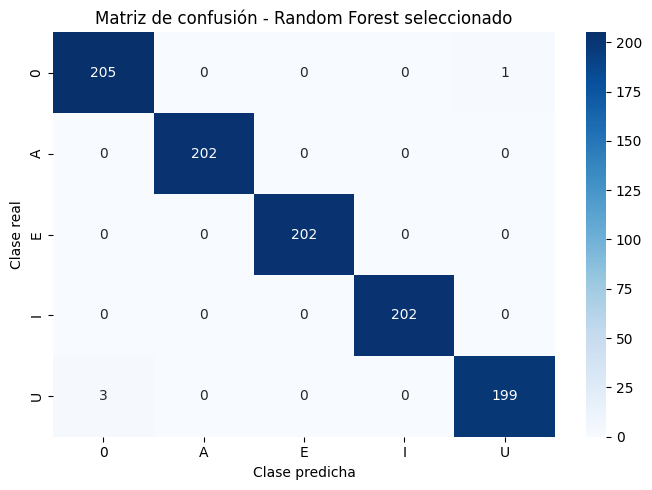

In [ ]:
modelo_rf_final = Pipeline([
    ("pca", PCA(n_components=0.95, random_state=42)),
    ("random_forest", RandomForestClassifier(random_state=42)),
])

modelo_rf_final.fit(X_train, y_train)

pred_rf_final_train = modelo_rf_final.predict(X_train)
pred_rf_final_test = modelo_rf_final.predict(X_test)

for conjunto, reales, predicciones_rf in [
    ("Entrenamiento", y_train, pred_rf_final_train),
    ("Prueba", y_test, pred_rf_final_test),
]:
    print(
        f"{conjunto} — "
        f"Exactitud: {accuracy_score(reales, predicciones_rf):.2%} | "
        f"F1 macro: {f1_score(reales, predicciones_rf, average='macro'):.2%} | "
        f"Errores: {np.count_nonzero(reales != predicciones_rf)}"
    )

print("\nReporte de clasificación del Random Forest seleccionado")
print(classification_report(
    y_test,
    pred_rf_final_test,
    target_names=label_encoder.classes_,
    digits=4,
))

matriz_rf_final = confusion_matrix(y_test, pred_rf_final_test)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_rf_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Matriz de confusión - Random Forest seleccionado")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

## Conclusión y análisis de resultados

**Selección de hiperparámetros.** Se comparó el bosque base, configurado con los hiperparámetros predeterminados y la semilla 42, con la mejor alternativa obtenida mediante `GridSearchCV`. El bosque base alcanzó una exactitud media de **99,75 %** y una desviación estándar de **0,00 puntos porcentuales**, mientras que el bosque ajustado obtuvo **98,62 %** y una desviación de **0,18 puntos porcentuales**. La mejor configuración ajustada utilizó 150 árboles, profundidad máxima de 5, cuatro variables candidatas por división, mínimo de dos muestras por hoja y mínimo de dos muestras para dividir un nodo. Como el bosque base obtuvo mayor exactitud media, se conservó como la configuración seleccionada.

**Selección de la representación.** El bosque base se comparó con y sin PCA mediante cinco particiones de validación cruzada. La versión con PCA alcanzó una exactitud media de **99,7535 %** y una desviación estándar de **0,078 puntos porcentuales**. La versión sin PCA obtuvo **99,7041 %** y una desviación de **0,126 puntos porcentuales**. Aunque la diferencia fue de aproximadamente **0,05 puntos porcentuales**, PCA obtuvo la mayor exactitud media y menor variación, por lo que fue seleccionado como representación de entrada.

**Evaluación en el conjunto de prueba.** El `Pipeline` final, compuesto por PCA y Random Forest, clasificó correctamente **1.010 de las 1.014 imágenes**, con una exactitud y un F1 macro de **99,61 %**. Reconoció correctamente todas las imágenes de las vocales A, E e I. Los cuatro errores se concentraron entre las clases `0` y U: una imagen de la clase `0` fue clasificada como U y tres imágenes de U fueron clasificadas como `0`.

**Análisis del ajuste.** El modelo alcanzó 100 % en entrenamiento y 99,61 % en prueba, lo que representa una diferencia de **0,39 puntos porcentuales**. El desempeño muestra una generalización alta dentro de esta partición, aunque debe comprobarse posteriormente con imágenes de otros autores y condiciones de captura.

## Guardado del modelo Random Forest seleccionado

Se guarda con `joblib` el `Pipeline` final que integra la transformación PCA y el Random Forest seleccionado. Al conservar ambos pasos en un mismo archivo, las nuevas imágenes aplanadas pueden entregarse directamente al modelo sin aplicar PCA manualmente por separado.

In [ ]:


ruta_rf_final = RUTA_MODELOS / "random_forest_final.pkl"

joblib.dump(modelo_rf_final, ruta_rf_final)

print(f"Random Forest seleccionado guardado correctamente en: {ruta_rf_final}")

Random Forest seleccionado guardado correctamente en: /content/ocr_vocales/salidas/MODELS/random_forest_final.pkl


# Árbol de decisión

Un árbol de decisión clasifica cada imagen mediante una serie de reglas. En cada nodo interno, el árbol divide las muestras según el valor de una característica. Al llegar a una hoja, asigna una clase.

Primero se ajustó un árbol que utilizaba componentes principales como entrada. Después se compararon dos representaciones de las imágenes con la misma malla de hiperparámetros y las mismas cinco particiones de validación cruzada: los componentes principales, con PCA ajustado dentro de cada partición, y los valores de píxel de las imágenes aplanadas. La configuración seleccionada en validación cruzada se evaluó sobre las mismas imágenes de prueba que el árbol original.

## Importación de bibliotecas

In [ ]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import GridSearchCV
import time
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt



## Configuración de la búsqueda de hiperparámetros

In [ ]:
# Instanciar el modelo base
dt_base = DecisionTreeClassifier(random_state=42)

# Definir la malla de hiperparámetros a explorar
param_grid_dt = {
    'criterion': ['gini', 'entropy'],      # Medida de calidad de la división
    'max_depth': [10, 15, 20, None],       # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],       # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4]          # Mínimo de muestras en una hoja
}

# Configurar GridSearchCV con validación cruzada (cv=5)
grid_search_dt = GridSearchCV(
    estimator=dt_base,
    param_grid=param_grid_dt,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

La malla combina dos criterios de división (Gini y entropía), cuatro opciones de profundidad máxima y tres valores para cada uno de los mínimos de muestras por nodo y por hoja. En total, `GridSearchCV` compara 72 configuraciones mediante validación cruzada de cinco particiones, usando la exactitud media como criterio de selección.

Esta búsqueda preliminar utiliza las imágenes de entrenamiento transformadas previamente con PCA (X_train_pca). Como el PCA se ajustó antes de las particiones internas de validación cruzada, este resultado se conserva únicamente como referencia y no se utiliza para seleccionar el árbol definitivo. El conjunto de prueba permaneció completamente aislado.

## Árbol preliminar con PCA

Se ejecutó `GridSearchCV` sobre los datos de entrenamiento transformados con PCA (`X_train_pca`). Se evaluaron las 72 configuraciones de la malla mediante validación cruzada de cinco particiones y se seleccionó la que obtuvo la mayor exactitud media.

Este resultado se conserva como referencia preliminar. La selección definitiva se realiza posteriormente mediante un Pipeline, que ajusta PCA dentro de cada partición de validación cruzada y permite compararlo rigurosamente con el árbol sin PCA.

In [ ]:

print("--- Iniciando optimización de Árbol de Decisión ---")
inicio_dt = time.time()

# Ajustar el modelo usando los datos de entrenamiento con dimensionalidad reducida
grid_search_dt.fit(X_train_pca, y_train)

tiempo_fin_dt = time.time() - inicio_dt
print(f"Entrenamiento finalizado en {tiempo_fin_dt:.2f} segundos.")
print(f"Mejores hiperparámetros encontrados: {grid_search_dt.best_params_}")
print(f"Mejor exactitud media en validación cruzada: {grid_search_dt.best_score_:.4f}")

# Extraer el mejor modelo
mejor_modelo_dt = grid_search_dt.best_estimator_

--- Iniciando optimización de Árbol de Decisión ---
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Entrenamiento finalizado en 160.90 segundos.
Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mejor exactitud media en validación cruzada: 0.9450


## Comparación del árbol con y sin PCA

Se comparan dos representaciones para el árbol de decisión: los 1.024 valores de píxel de las imágenes aplanadas y los componentes principales que retienen al menos el 95 % de la varianza de entrenamiento. Las dos alternativas se evalúan con la misma malla de hiperparámetros y las mismas cinco particiones de validación cruzada. Cuando se usa PCA, se ajusta dentro de cada partición de entrenamiento mediante un `Pipeline`. La elección se basa en la exactitud media en validación cruzada.

In [ ]:
from tempfile import TemporaryDirectory
from sklearn.pipeline import Pipeline

malla_arbol = {
    f"arbol__{nombre}": valores
    for nombre, valores in param_grid_dt.items()
}

with TemporaryDirectory() as cache_pca:
    pipeline_dt = Pipeline(
        [
            ("pca", "passthrough"),
            ("arbol", DecisionTreeClassifier(random_state=42)),
        ],
        memory=cache_pca,
    )

    busqueda_dt_representacion = GridSearchCV(
        estimator=pipeline_dt,
        param_grid={
            "pca": ["passthrough", PCA(n_components=0.95, random_state=42)],
            **malla_arbol,
        },
        cv=5,
        scoring="accuracy",
        n_jobs=2,
        refit=False,
        verbose=1,
    )
    busqueda_dt_representacion.fit(X_train, y_train)

resultados_dt = pd.DataFrame(busqueda_dt_representacion.cv_results_)
resultados_dt["Representación"] = resultados_dt["param_pca"].map(
    lambda paso: "Sin PCA" if paso == "passthrough" else "Con PCA"
)

mejores_dt = (
    resultados_dt.sort_values("mean_test_score", ascending=False, kind="stable")
    .drop_duplicates("Representación")
)

for _, fila in mejores_dt.iterrows():
    print(f"\n{fila['Representación']}")
    print(f"Exactitud media: {fila['mean_test_score']:.2%}")
    print(f"Desviación estándar: {100 * fila['std_test_score']:.2f} puntos porcentuales")
    print({
        nombre.removeprefix("arbol__"): fila["params"][nombre]
        for nombre in malla_arbol
    })

Fitting 5 folds for each of 144 candidates, totalling 720 fits

Sin PCA
Exactitud media: 96.43%
Desviación estándar: 0.93 puntos porcentuales
{'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 1}

Con PCA
Exactitud media: 93.89%
Desviación estándar: 0.41 puntos porcentuales
{'criterion': 'entropy', 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 1}


## Evaluación de los árboles en el conjunto de prueba
Se evaluaron ambos árboles sobre las mismas 1.014 imágenes de prueba. El árbol original recibió los componentes principales (`X_test_pca`) y el árbol seleccionado sin PCA recibió los 1.024 valores de píxel de cada imagen aplanada (`X_test`). Se presentan los reportes por vocal y las matrices de confusión de ambos modelos.

### Árbol original con PCA


=== REPORTE DE CLASIFICACIÓN (ÁRBOL DE DECISIÓN) ===
              precision    recall  f1-score   support

           0       0.93      0.96      0.95       206
           A       0.95      0.94      0.95       202
           E       0.99      0.95      0.97       202
           I       0.93      0.96      0.94       202
           U       0.94      0.94      0.94       202

    accuracy                           0.95      1014
   macro avg       0.95      0.95      0.95      1014
weighted avg       0.95      0.95      0.95      1014



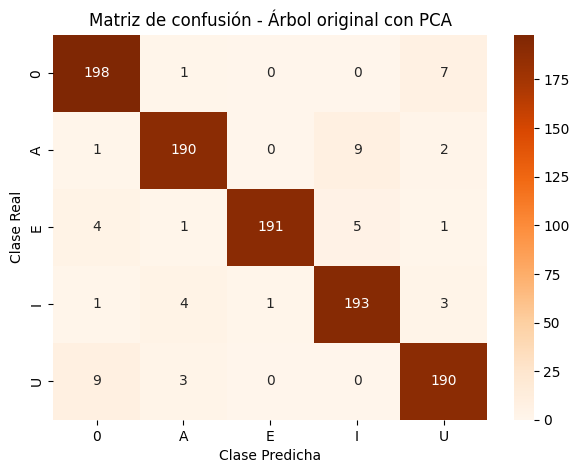

In [ ]:
# Predecir sobre el conjunto de prueba
y_pred_dt = mejor_modelo_dt.predict(X_test_pca)

# Imprimir el reporte
print("\n=== REPORTE DE CLASIFICACIÓN (ÁRBOL DE DECISIÓN) ===")
print(classification_report(y_test, y_pred_dt, target_names=label_encoder.classes_))

# Generar y graficar la matriz de confusión
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Matriz de confusión - Árbol original con PCA")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show()

### Árbol seleccionado sin PCA

In [ ]:
# Recuperar los hiperparámetros ganadores del árbol sin PCA
fila_sin_pca = mejores_dt.loc[mejores_dt["Representación"] == "Sin PCA"].iloc[0]
parametros_sin_pca = {
    nombre.removeprefix("arbol__"): fila_sin_pca["params"][nombre]
    for nombre in malla_arbol
}

# Entrenar y evaluar usando directamente los píxeles aplanados
modelo_dt_sin_pca = DecisionTreeClassifier(
    random_state=42, **parametros_sin_pca
)
modelo_dt_sin_pca.fit(X_train, y_train)
y_pred_dt_sin_pca = modelo_dt_sin_pca.predict(X_test)

errores_dt_sin_pca = np.count_nonzero(y_test != y_pred_dt_sin_pca)
print(f"Exactitud en prueba: {accuracy_score(y_test, y_pred_dt_sin_pca):.2%}")
print(f"Errores en prueba: {errores_dt_sin_pca} de {len(y_test):,}")
errores_dt_original = np.count_nonzero(y_test != y_pred_dt)
print(
    f"Errores menos frente al árbol original: "
    f"{errores_dt_original - errores_dt_sin_pca}"
)

print(classification_report(
    y_test, y_pred_dt_sin_pca,
    target_names=label_encoder.classes_,
    digits=4,
))

Exactitud en prueba: 96.25%
Errores en prueba: 38 de 1,014
Errores menos frente al árbol original: 14
              precision    recall  f1-score   support

           0     0.9384    0.9612    0.9496       206
           A     0.9799    0.9653    0.9726       202
           E     0.9752    0.9752    0.9752       202
           I     0.9372    0.9604    0.9487       202
           U     0.9846    0.9505    0.9673       202

    accuracy                         0.9625      1014
   macro avg     0.9631    0.9625    0.9627      1014
weighted avg     0.9630    0.9625    0.9626      1014



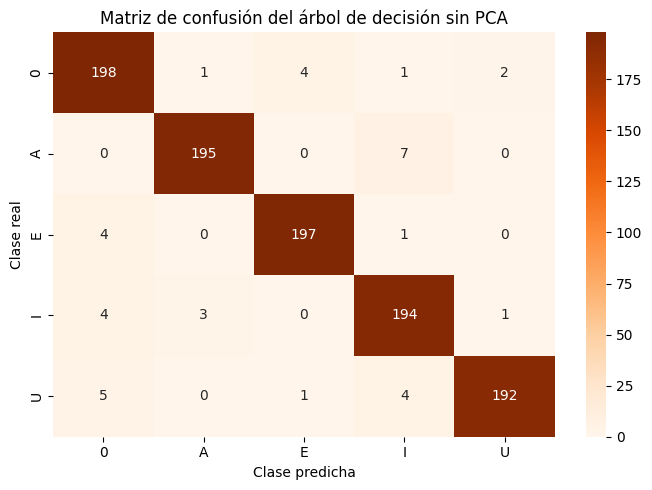

In [ ]:
cm_dt_sin_pca = confusion_matrix(y_test, y_pred_dt_sin_pca)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_dt_sin_pca,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Matriz de confusión del árbol de decisión sin PCA")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

## Visualización y análisis de ajuste

Se compara la exactitud del árbol seleccionado sin PCA en entrenamiento y prueba. También se visualizan sus primeras divisiones para observar qué píxeles usa el modelo al clasificar las imágenes.

In [ ]:
acc_train_dt_sin_pca = modelo_dt_sin_pca.score(X_train, y_train)
acc_test_dt_sin_pca = accuracy_score(y_test, y_pred_dt_sin_pca)
brecha_dt_sin_pca = 100 * (acc_train_dt_sin_pca - acc_test_dt_sin_pca)

print(f"Exactitud en entrenamiento: {acc_train_dt_sin_pca:.2%}")
print(f"Exactitud en prueba: {acc_test_dt_sin_pca:.2%}")
print(f"Brecha entre entrenamiento y prueba: {brecha_dt_sin_pca:.2f} puntos porcentuales")

Exactitud en entrenamiento: 99.83%
Exactitud en prueba: 96.25%
Brecha entre entrenamiento y prueba: 3.57 puntos porcentuales


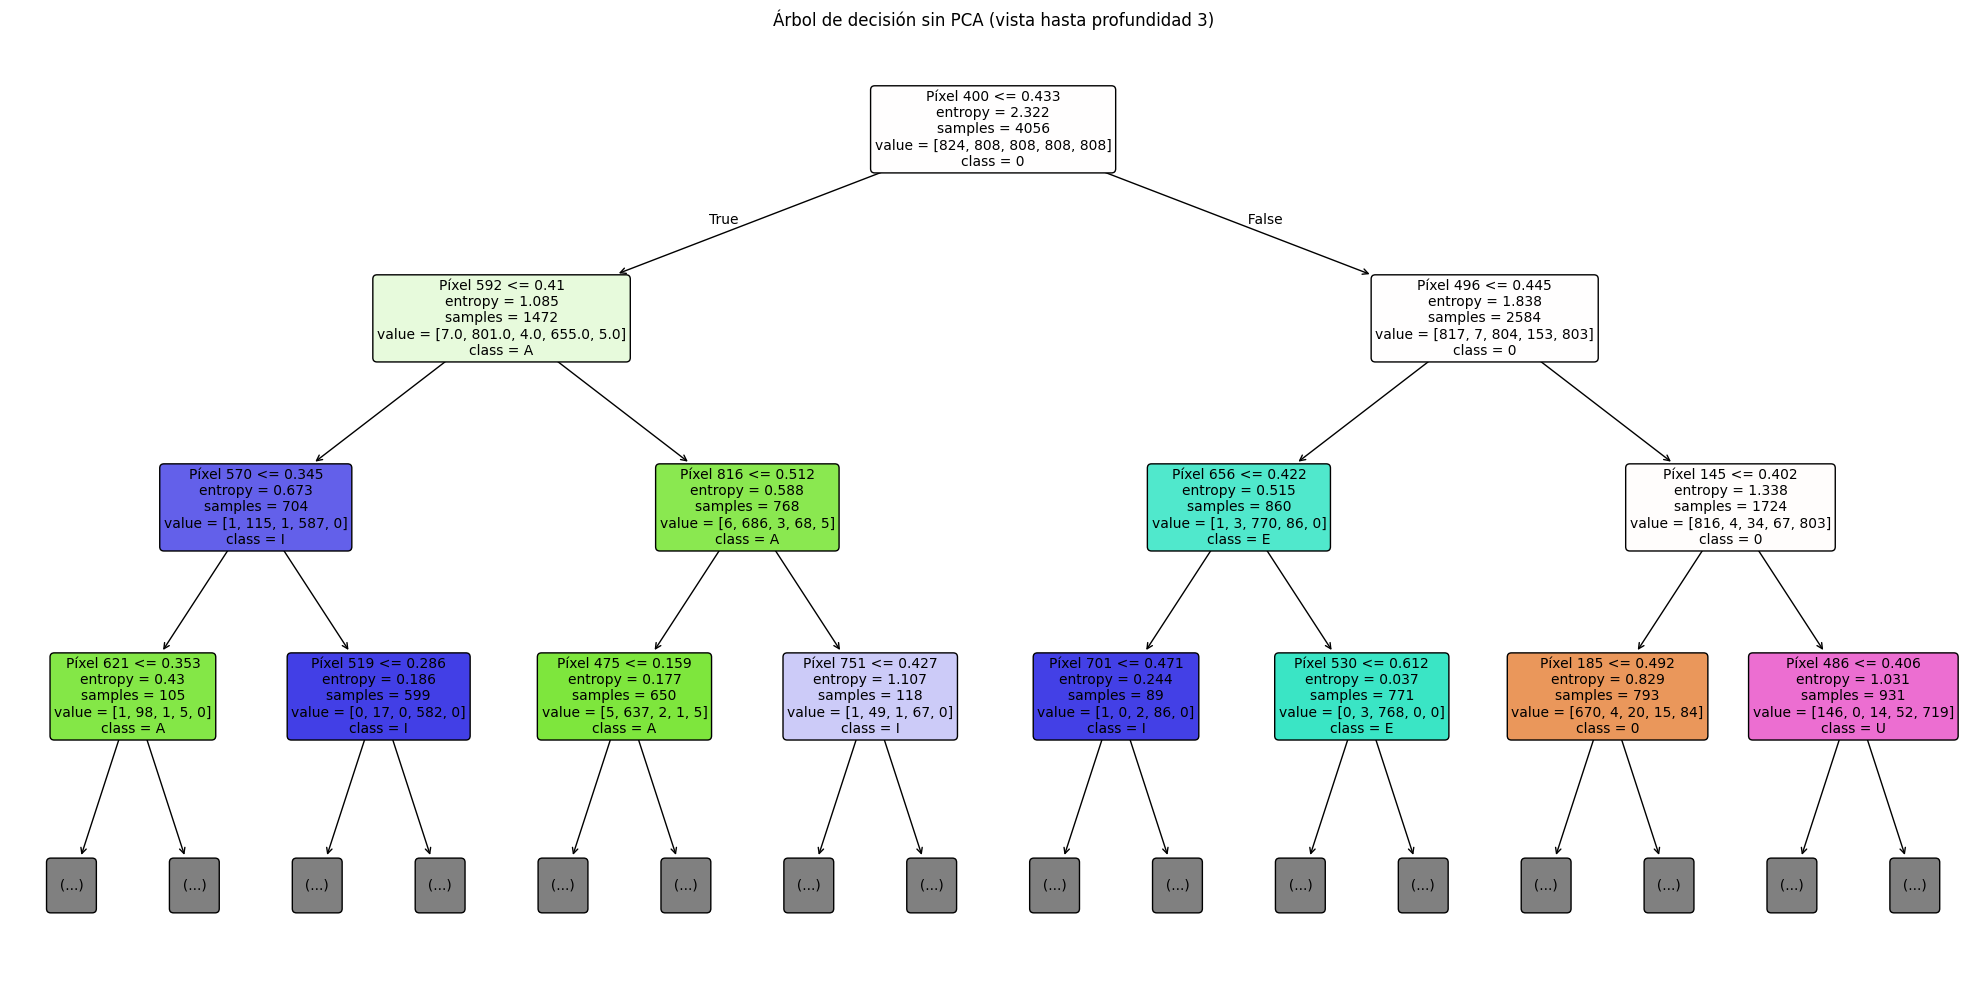

In [ ]:
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_dt_sin_pca,
    max_depth=3,
    feature_names=[f"Píxel {i + 1}" for i in range(X_train.shape[1])],
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Árbol de decisión sin PCA (vista hasta profundidad 3)")
plt.tight_layout()
plt.show()

## Conclusión y análisis de resultados

**Selección de la representación.** Utilizando la misma malla de hiperparámetros y las mismas cinco particiones de validación cruzada, el árbol sin PCA alcanzó una exactitud media de **96,43 %**, frente al **93,89 %** obtenido con PCA ajustado dentro de cada partición. Por este resultado se seleccionó el árbol sin PCA, configurado con el criterio de entropía, profundidad máxima de 10, mínimo de 5 muestras para dividir un nodo y mínimo de 1 muestra por hoja.

**Resultados en prueba.** Sobre las 1.014 imágenes de prueba, el árbol seleccionado clasificó correctamente **976 imágenes** y cometió **38 errores**, obteniendo una exactitud de **96,25 %**. El árbol original con PCA clasificó correctamente 962 imágenes y cometió 52 errores. Por tanto, la representación sin PCA permitió reducir 14 errores y aumentar la exactitud aproximadamente 1,38 puntos porcentuales.

**Análisis de ajuste.** El árbol seleccionado alcanzó **99,83 %** de exactitud en entrenamiento y **96,25 %** en prueba, con una brecha de **3,57 puntos porcentuales**. Esta diferencia evidencia cierto ajuste a los datos de entrenamiento, propio de la flexibilidad de los árboles de decisión. Sin embargo, la cercanía entre la exactitud de validación cruzada (**96,43 %**) y la exactitud de prueba (**96,25 %**) indica que su comportamiento se mantuvo estable ante datos no utilizados durante el entrenamiento.

## Guardado del árbol de decisión seleccionado

El árbol sin PCA se guardó con `joblib` en el archivo `decision_tree_sin_pca.pkl`, dentro del entorno local de Colab. Para clasificar nuevas imágenes, se aplica el mismo preprocesamiento usado durante el entrenamiento y se aplana cada imagen de 32 × 32 píxeles en un vector de 1.024 valores. Ese vector se entrega directamente al árbol.

In [ ]:
ruta_dt_sin_pca = RUTA_MODELOS / "decision_tree_sin_pca.pkl"
joblib.dump(modelo_dt_sin_pca, ruta_dt_sin_pca)

print(f"Árbol seleccionado guardado en: {ruta_dt_sin_pca}")

Árbol seleccionado guardado en: /content/ocr_vocales/salidas/MODELS/decision_tree_sin_pca.pkl


# Red neuronal de tipo perceptrón multicapa (MLP)

El perceptrón multicapa es una red neuronal que combina las características de entrada en una o más capas ocultas para clasificar cada imagen en una de las cinco clases del proyecto. En este experimento, la red recibe los 94 componentes principales obtenidos a partir de las imágenes de 32 × 32 píxeles.

Con `GridSearchCV` se comparan 18 configuraciones que varían la arquitectura de las capas ocultas, la regularización y la tasa de aprendizaje inicial. La configuración se selecciona por su exactitud media en cinco particiones de validación cruzada y se evalúa después en el conjunto de prueba.

## Importación de bibliotecas y carga de los datos transformados

Se importan las bibliotecas para configurar, entrenar y evaluar el perceptrón multicapa. También se cargan el PCA ya ajustado y los conjuntos de entrenamiento y prueba transformados en la etapa de preprocesamiento. Cada imagen está representada por 94 componentes principales, que se usan como entrada de la red.



In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib
import numpy as np  # Necesario para cargar el archivo .npz
from pathlib import Path

# --- Carga del PCA y Datos guardados (por reinicio del entorno) ---
ruta_pca = RUTA_MODELOS / "pca_transform.pkl"
ruta_datos = RUTA_MODELOS / "datos_transformados_pca.npz"

# 1. Si el pca ya está en memoria de los pasos anteriores, esta línea sirve como respaldo
pca = joblib.load(ruta_pca)
print("Dependencias importadas y modelo PCA cargado exitosamente desde el entorno de Colab.")

# 2. Cargar y sobrescribir los conjuntos de datos transformados
# Cargar la transformación PCA guardada durante el preprocesamiento
datos_cargados = np.load(ruta_datos)

X_train_pca = datos_cargados['X_train_pca']
X_test_pca = datos_cargados['X_test_pca']
y_train = datos_cargados['y_train']
y_test = datos_cargados['y_test']

print(f"Datos cargados desde el entorno de Colab. Dimensiones de X_train_pca: {X_train_pca.shape}")
print("¡Variables en memoria sobrescritas! Todo listo para configurar y entrenar la red neuronal.")

Dependencias importadas y modelo PCA cargado exitosamente desde el entorno de Colab.
Datos cargados desde el entorno de Colab. Dimensiones de X_train_pca: (4056, 94)
¡Variables en memoria sobrescritas! Todo listo para configurar y entrenar la red neuronal.


## Configuración de la búsqueda de hiperparámetros

En todas las configuraciones se usa ReLU como función de activación en las capas ocultas y Adam como optimizador. Se fija un máximo de 1.000 iteraciones y se usa la semilla 42.

La búsqueda combina tres decisiones:

- **Arquitectura de la red.** Se prueban dos redes de una capa oculta, con 50 o 100 neuronas, y una red de dos capas ocultas, con 50 neuronas en la primera y 25 en la segunda.
- **Regularización L2 (`alpha`).** Se prueban 0,0001, 0,001 y 0,01. Un valor mayor aumenta la penalización sobre los pesos de la red.
- **Tasa de aprendizaje inicial (`learning_rate_init`).** Se prueban 0,001 y 0,0001. Este valor determina la escala inicial de las actualizaciones de los pesos.

Las 18 combinaciones se comparan con `GridSearchCV` mediante validación cruzada de cinco particiones. Se selecciona la que obtiene la mayor exactitud media.

In [ ]:
print("--- Configuración de la Red Neuronal (MLP) ---")
# Instanciamos el modelo base.
mlp_base = MLPClassifier(solver='adam', activation='relu', max_iter=1000, random_state=42)

# Definición de la malla de hiperparámetros
param_grid_mlp = {
    # Exploramos 1 capa oculta (50 o 100 neuronas) y 2 capas ocultas (50 y 25 neuronas)
    'hidden_layer_sizes': [(50,), (100,), (50, 25)],
    # Regularización L2 (alpha)
    'alpha': [0.0001, 0.001, 0.01],
    # Tasa de aprendizaje inicial
    'learning_rate_init': [0.001, 0.0001]
}

# Configuración de GridSearchCV (Validación Cruzada cv=5)
grid_search_mlp = GridSearchCV(
    estimator=mlp_base,
    param_grid=param_grid_mlp,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
print("Configuración de hiperparámetros y GridSearchCV lista.")

--- Configuración de la Red Neuronal (MLP) ---
Configuración de hiperparámetros y GridSearchCV lista.


## Entrenamiento del perceptrón multicapa

Se evaluaron 18 configuraciones del MLP mediante validación cruzada de cinco particiones. La configuración seleccionada obtuvo una exactitud media del 99,90 % y utilizó dos capas ocultas de 50 y 25 neuronas, una regularización L2 de 0,0001 y una tasa de aprendizaje inicial de 0,001. Después de la búsqueda, esta configuración se volvió a entrenar con las 4.056 imágenes de entrenamiento representadas por 94 componentes principales.

In [ ]:
print("--- Iniciando Entrenamiento de la Red Neuronal ---")
inicio_mlp = time.time()

# Entrenamiento EXCLUSIVO sobre el conjunto transformado por PCA
grid_search_mlp.fit(X_train_pca, y_train)

tiempo_fin_mlp = time.time() - inicio_mlp
mejor_modelo_mlp = grid_search_mlp.best_estimator_

print(f"¡Entrenamiento finalizado en {tiempo_fin_mlp:.2f} segundos!")
print(f"Mejores hiperparámetros encontrados: {grid_search_mlp.best_params_}")
print(f"Mejor precisión en validación cruzada (Train): {grid_search_mlp.best_score_:.4f}")

--- Iniciando Entrenamiento de la Red Neuronal ---
Fitting 5 folds for each of 18 candidates, totalling 90 fits
¡Entrenamiento finalizado en 179.24 segundos!
Mejores hiperparámetros encontrados: {'alpha': 0.0001, 'hidden_layer_sizes': (50, 25), 'learning_rate_init': 0.001}
Mejor precisión en validación cruzada (Train): 0.9990


## Resultados de la búsqueda de hiperparámetros

La tabla presenta las cinco configuraciones con mayor exactitud media en validación cruzada. La desviación estándar, expresada en puntos porcentuales, indica cuánto variaron sus resultados entre las cinco particiones.

In [ ]:
resultados_mlp = pd.DataFrame(grid_search_mlp.cv_results_)

tabla_mlp = (
    resultados_mlp.sort_values("rank_test_score", kind="stable")
    .head(5)
    .loc[:, [
        "param_hidden_layer_sizes",
        "param_alpha",
        "param_learning_rate_init",
        "mean_test_score",
        "std_test_score",
    ]]
    .rename(columns={
        "param_hidden_layer_sizes": "Capas ocultas",
        "param_alpha": "Regularización L2",
        "param_learning_rate_init": "Tasa inicial",
        "mean_test_score": "Exactitud media",
        "std_test_score": "Desviación estándar",
    })
)

display(tabla_mlp.style.format({
    "Exactitud media": "{:.4%}",
    "Desviación estándar": lambda valor: f"{100 * valor:.3f} pp",
}).hide(axis="index"))

Capas ocultas,Regularización L2,Tasa inicial,Exactitud media,Desviación estándar
"(50, 25)",0.000100,0.001000,99.9014%,0.092 pp
"(50, 25)",0.001000,0.001000,99.9014%,0.092 pp
"(50, 25)",0.010000,0.001000,99.9014%,0.092 pp
"(50,)",0.000100,0.001000,99.8768%,0.110 pp
"(50,)",0.001000,0.001000,99.8768%,0.110 pp


## Comparación del MLP con y sin PCA

Para determinar si la reducción de dimensionalidad beneficia al perceptrón multicapa, se compara la misma configuración de red utilizando dos representaciones: los 1.024 píxeles aplanados y los componentes principales que conservan al menos el 95 % de la varianza. El PCA se ajusta dentro de cada partición de entrenamiento para evitar que la validación contribuya a calcular los componentes. La selección se basa exclusivamente en la exactitud media de validación cruzada.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
import pandas as pd

# Misma configuración ganadora para ambas representaciones
mlp_comparacion = MLPClassifier(
    hidden_layer_sizes=(50, 25),
    alpha=0.0001,
    learning_rate_init=0.001,
    solver="adam",
    activation="relu",
    max_iter=1000,
    random_state=42,
)

pipeline_mlp_representacion = Pipeline([
    ("pca", "passthrough"),
    ("mlp", mlp_comparacion),
])

# Solo se comparan las dos representaciones; no se repite la malla de 18 configuraciones
busqueda_mlp_representacion = GridSearchCV(
    estimator=pipeline_mlp_representacion,
    param_grid={
        "pca": [
            "passthrough",
            PCA(n_components=0.95, random_state=42),
        ]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    refit=False,
    verbose=1,
)

busqueda_mlp_representacion.fit(X_train, y_train)

resultados_mlp_representacion = pd.DataFrame(
    busqueda_mlp_representacion.cv_results_
)

resultados_mlp_representacion["Representación"] = (
    resultados_mlp_representacion["param_pca"].map(
        lambda paso: "Sin PCA" if paso == "passthrough" else "Con PCA"
    )
)

tabla_mlp_representacion = (
    resultados_mlp_representacion[[
        "Representación",
        "mean_test_score",
        "std_test_score",
        "mean_fit_time",
    ]]
    .rename(columns={
        "mean_test_score": "Exactitud media",
        "std_test_score": "Desviación estándar",
        "mean_fit_time": "Tiempo medio por ajuste (s)",
    })
    .sort_values("Exactitud media", ascending=False)
)

display(
    tabla_mlp_representacion.style.format({
        "Exactitud media": "{:.4%}",
        "Desviación estándar": lambda valor: f"{100 * valor:.3f} pp",
        "Tiempo medio por ajuste (s)": "{:.2f}",
    }).hide(axis="index")
)

Fitting 5 folds for each of 2 candidates, totalling 10 fits


Representación,Exactitud media,Desviación estándar,Tiempo medio por ajuste (s)
Con PCA,99.8768%,0.078 pp,2.55
Sin PCA,99.8028%,0.126 pp,11.66


### Selección de la representación

El MLP con PCA obtuvo una exactitud media de **99,8768 %**, ligeramente superior al **99,8028 %** alcanzado sin PCA. También presentó menor variación entre las particiones, con una desviación estándar de **0,078 puntos porcentuales**, frente a **0,126 puntos porcentuales** sin PCA.

Además, el tiempo medio de ajuste disminuyó de 11,66 a 2,55 segundos. Por tanto, se conserva la representación con PCA porque ofreció una exactitud ligeramente mayor, mayor estabilidad y un entrenamiento considerablemente más rápido utilizando solo 94 componentes en lugar de 1.024 píxeles.

## Curva de pérdida del MLP seleccionado

La curva muestra la pérdida en cada iteración del ajuste final del MLP sobre el conjunto de entrenamiento. Permite observar cómo evolucionó la optimización de los pesos.

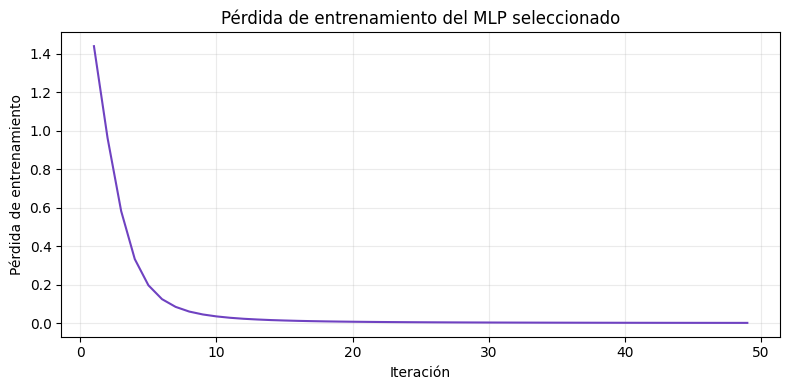

In [ ]:
perdida_mlp = mejor_modelo_mlp.loss_curve_

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(perdida_mlp) + 1), perdida_mlp, color="#6F42C1")
ax.set_title("Pérdida de entrenamiento del MLP seleccionado")
ax.set_xlabel("Iteración")
ax.set_ylabel("Pérdida de entrenamiento")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Evaluación del MLP en el conjunto de prueba

El modelo seleccionado se evaluó sobre las 1.014 imágenes de prueba transformadas con el PCA ajustado en entrenamiento. Se reportan la exactitud global, la precisión, la sensibilidad y el F1 por clase. La matriz de confusión permite identificar qué vocales confundió el modelo.

--- Prueba y Evaluación Final (Conjunto de Prueba) ---
Exactitud en prueba: 99.70%
Errores en prueba: 3 de 1014
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       206
           A       1.00      0.99      1.00       202
           E       1.00      1.00      1.00       202
           I       0.99      1.00      1.00       202
           U       1.00      1.00      1.00       202

    accuracy                           1.00      1014
   macro avg       1.00      1.00      1.00      1014
weighted avg       1.00      1.00      1.00      1014



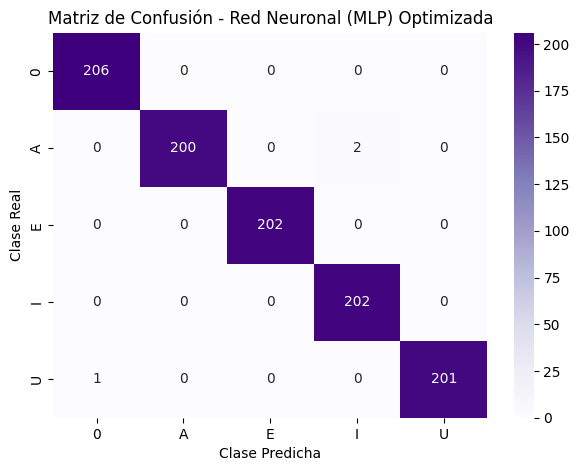

In [ ]:
print("--- Prueba y Evaluación Final (Conjunto de Prueba) ---")
# Predicción sobre el conjunto de prueba aislado (transformado por PCA)
y_pred_mlp = mejor_modelo_mlp.predict(X_test_pca)
acc_test_mlp = accuracy_score(y_test, y_pred_mlp)

print(f"Exactitud en prueba: {acc_test_mlp:.2%}")
print(f"Errores en prueba: {np.count_nonzero(y_test != y_pred_mlp)} de {len(y_test)}")
print(classification_report(
    y_test,
    y_pred_mlp,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0,
))

# Matriz de Confusión
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Purples',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Matriz de Confusión - Red Neuronal (MLP) Optimizada")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show()

## Conclusión y análisis de resultados

**Selección de la representación.** Al utilizar la misma arquitectura en las mismas cinco particiones de validación cruzada, el MLP con PCA alcanzó una exactitud media de **99,8768 %**, frente al **99,8028 %** obtenido sin PCA. La representación con PCA también presentó menor variación y redujo el tiempo medio de entrenamiento de 11,66 a 2,55 segundos. Por estas razones se conservaron los 94 componentes principales como entrada del modelo.

**Selección de la configuración.** Entre las 18 configuraciones evaluadas mediante validación cruzada, la seleccionada utilizó dos capas ocultas de 50 y 25 neuronas, regularización L2 de 0,0001 y una tasa de aprendizaje inicial de 0,001. Esta configuración obtuvo aproximadamente **99,90 %** de exactitud media.

**Resultados en prueba.** El MLP clasificó correctamente **1.011 de las 1.014 imágenes**, alcanzando una exactitud de **99,70 %**. Confundió dos imágenes reales de la vocal A con la vocal I y una imagen de U con la clase `0`. Reconoció correctamente todas las imágenes reales de las clases `0`, E e I.

**Alcance del resultado.** La proximidad entre la validación cruzada y la prueba indica un comportamiento estable en esta partición. Sin embargo, para comprobar su capacidad de generalización ante estilos de escritura diferentes sería necesaria una evaluación externa con imágenes procedentes de otras personas o fuentes.

## Guardado del modelo MLP

El perceptrón multicapa se guardó con `joblib` en el archivo `mlp_model.pkl`, dentro del entorno local de Colab. Para clasificar nuevas imágenes se aplica el mismo preprocesamiento y la transformación PCA ajustada durante el entrenamiento antes de entregar los componentes al modelo.

In [ ]:
print("\n--- Persistencia del Modelo ---")
# Guardado del modelo en el directorio de salida
ruta_mlp = RUTA_MODELOS / "mlp_model.pkl"
joblib.dump(mejor_modelo_mlp, ruta_mlp)
print(f"¡Modelo de Red Neuronal guardado exitosamente en: {ruta_mlp.name}!")


--- Persistencia del Modelo ---
¡Modelo de Red Neuronal guardado exitosamente en: mlp_model.pkl!


# Regresión logística multiclase (Softmax)

La regresión logística multiclase estima la probabilidad de que una imagen pertenezca a cada una de las cinco clases y predice la clase con mayor probabilidad. En esta corrida, el modelo recibe 94 componentes principales por imagen.

## Importación de bibliotecas y carga de los datos transformados

In [ ]:
import joblib
import numpy as np
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import joblib
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Preparación para Regresión Multivariada (SoftMax) ---")
# --- Carga de los datos transformados mediante PCA ---
# Asegúrate de que la ruta coincide con la que creamos ayer
ruta_datos = RUTA_MODELOS / "datos_transformados_pca.npz"

try:
    # Sobrescribimos las variables en memoria con los datos del Drive
    datos_cargados = np.load(ruta_datos)
    X_train_pca = datos_cargados['X_train_pca']
    X_test_pca = datos_cargados['X_test_pca']
    y_train = datos_cargados['y_train']
    y_test = datos_cargados['y_test']

    print(f"¡Datos PCA cargados exitosamente desde el entorno de Colab!")
    print(f"Dimensiones listas para entrenar -> X_train_pca: {X_train_pca.shape}")
except FileNotFoundError:
    print(f"[ERROR] No se encontró el archivo en {ruta_datos}. Verifica que la etapa de PCA se haya ejecutado correctamente.")

--- Preparación para Regresión Multivariada (SoftMax) ---
¡Datos PCA cargados exitosamente desde el entorno de Colab!
Dimensiones listas para entrenar -> X_train_pca: (4056, 94)


## Configuración de la búsqueda de hiperparámetros

La búsqueda combina cinco valores de `C` (0,01, 0,1, 1, 10 y 100) y dos optimizadores (`lbfgs` y `saga`). Un valor menor de `C` aplica una regularización más fuerte. Las 10 configuraciones se comparan mediante validación cruzada de cinco particiones y se selecciona la de mayor exactitud media.

In [ ]:
print("--- Configuración de la Regresión SoftMax ---")
# Instanciamos el modelo base indicando que es un problema multiclase (multinomial/SoftMax)
# Aumentamos max_iter para asegurar que el algoritmo de optimización converja
softmax_base = LogisticRegression(max_iter=1500, random_state=42)

# Definición de la malla de hiperparámetros
param_grid_softmax = {
    # 'C' es el inverso de la fuerza de regularización (menor valor = mayor regularización)
    'C': [0.01, 0.1, 1, 10, 100],
    # Solvers recomendados para problemas multiclase
    'solver': ['lbfgs', 'saga']
}

# Configuración de GridSearchCV con validación cruzada (cv=5)
grid_search_softmax = GridSearchCV(
    estimator=softmax_base,
    param_grid=param_grid_softmax,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
print("Configuración de hiperparámetros y GridSearchCV lista.")

--- Configuración de la Regresión SoftMax ---
Configuración de hiperparámetros y GridSearchCV lista.


## Entrenamiento de la regresión Softmax

Se ejecutó `GridSearchCV` sobre las 4.056 imágenes de entrenamiento, representadas por 94 componentes principales. Cada una de las 10 configuraciones se evaluó en cinco particiones. La configuración con mayor exactitud media se volvió a entrenar con todo el conjunto de entrenamiento.

In [ ]:
print("--- Iniciando Entrenamiento de la Regresión SoftMax ---")
inicio_softmax = time.time()

# Ajustamos el modelo con los datos de entrenamiento transformados
grid_search_softmax.fit(X_train_pca, y_train)

tiempo_fin_softmax = time.time() - inicio_softmax
mejor_modelo_softmax = grid_search_softmax.best_estimator_

print(f"¡Entrenamiento finalizado en {tiempo_fin_softmax:.2f} segundos!")
print(f"Mejores hiperparámetros encontrados: {grid_search_softmax.best_params_}")
print(f"Mejor precisión en validación cruzada (Train): {grid_search_softmax.best_score_:.4f}")

--- Iniciando Entrenamiento de la Regresión SoftMax ---
Fitting 5 folds for each of 10 candidates, totalling 50 fits
¡Entrenamiento finalizado en 138.26 segundos!
Mejores hiperparámetros encontrados: {'C': 100, 'solver': 'saga'}
Mejor precisión en validación cruzada (Train): 0.9990


## Resultados de la búsqueda de hiperparámetros

In [ ]:
resultados_softmax = pd.DataFrame(grid_search_softmax.cv_results_)

tabla_softmax = (
    resultados_softmax.sort_values("rank_test_score", kind="stable")
    [["param_C", "param_solver", "mean_test_score", "std_test_score"]]
    .rename(columns={
        "param_C": "C",
        "param_solver": "Optimizador",
        "mean_test_score": "Exactitud media",
        "std_test_score": "Desviación estándar",
    })
)

display(tabla_softmax.style.format({
    "Exactitud media": "{:.4%}",
    "Desviación estándar": lambda valor: f"{100 * valor:.3f} pp",
}).hide(axis="index"))

C,Optimizador,Exactitud media,Desviación estándar
100.000000,saga,99.9014%,0.092 pp
1.000000,lbfgs,99.8274%,0.099 pp
1.000000,saga,99.8274%,0.099 pp
10.000000,lbfgs,99.8274%,0.126 pp
10.000000,saga,99.8274%,0.126 pp
100.000000,lbfgs,99.7781%,0.164 pp
0.100000,lbfgs,99.2850%,0.275 pp
0.100000,saga,99.2850%,0.275 pp
0.010000,lbfgs,97.7071%,0.669 pp
0.010000,saga,97.7071%,0.669 pp


### Exactitud de Softmax según la regularización y el optimizador

La gráfica compara la exactitud media en validación cruzada para los cinco valores de `C` y los dos optimizadores. Un valor menor de `C` corresponde a una regularización más fuerte.

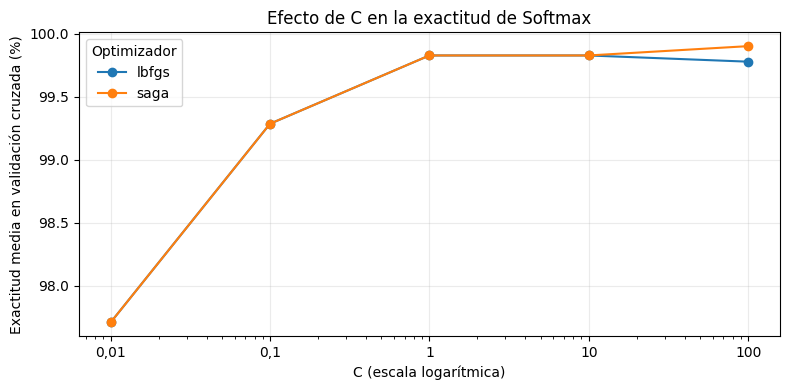

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))

for optimizador, grupo in resultados_softmax.groupby("param_solver"):
    grupo = grupo.sort_values("param_C")
    ax.plot(
        grupo["param_C"],
        grupo["mean_test_score"] * 100,
        marker="o",
        label=optimizador,
    )

ax.set_xscale("log")
ax.set_xticks([0.01, 0.1, 1, 10, 100], ["0,01", "0,1", "1", "10", "100"])
ax.set_xlabel("C (escala logarítmica)")
ax.set_ylabel("Exactitud media en validación cruzada (%)")
ax.set_title("Efecto de C en la exactitud de Softmax")
ax.legend(title="Optimizador")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Las curvas se superponen desde `C = 0.01` hasta `C = 10` porque ambos optimizadores obtuvieron la misma exactitud media en esos valores. Con `C = 100`, `saga` alcanzó el mejor resultado de la búsqueda (99,90 %), mientras que `lbfgs` obtuvo 99,78 %.

## Comparación de Softmax con y sin PCA

Se compara la misma configuración de regresión logística multiclase utilizando los 1.024 píxeles aplanados y los componentes principales que conservan al menos el 95 % de la varianza. El PCA se ajusta dentro de cada partición de entrenamiento para evitar filtraciones de información. La representación se selecciona mediante la exactitud media en cinco particiones de validación cruzada.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
import pandas as pd

# Configuración ganadora de Softmax
softmax_comparacion = LogisticRegression(
    C=100,
    solver="saga",
    max_iter=1500,
    random_state=42,
)

pipeline_softmax_representacion = Pipeline([
    ("pca", "passthrough"),
    ("softmax", softmax_comparacion),
])

# Se comparan únicamente las dos representaciones
busqueda_softmax_representacion = GridSearchCV(
    estimator=pipeline_softmax_representacion,
    param_grid={
        "pca": [
            "passthrough",
            PCA(n_components=0.95, random_state=42),
        ]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    refit=False,
    verbose=1,
)

busqueda_softmax_representacion.fit(X_train, y_train)

resultados_softmax_representacion = pd.DataFrame(
    busqueda_softmax_representacion.cv_results_
)

resultados_softmax_representacion["Representación"] = (
    resultados_softmax_representacion["param_pca"].map(
        lambda paso: "Sin PCA" if paso == "passthrough" else "Con PCA"
    )
)

tabla_softmax_representacion = (
    resultados_softmax_representacion[[
        "Representación",
        "mean_test_score",
        "std_test_score",
        "mean_fit_time",
    ]]
    .rename(columns={
        "mean_test_score": "Exactitud media",
        "std_test_score": "Desviación estándar",
        "mean_fit_time": "Tiempo medio por ajuste (s)",
    })
    .sort_values("Exactitud media", ascending=False)
)

display(
    tabla_softmax_representacion.style.format({
        "Exactitud media": "{:.4%}",
        "Desviación estándar": lambda valor: f"{100 * valor:.3f} pp",
        "Tiempo medio por ajuste (s)": "{:.2f}",
    }).hide(axis="index")
)

Fitting 5 folds for each of 2 candidates, totalling 10 fits


Representación,Exactitud media,Desviación estándar,Tiempo medio por ajuste (s)
Con PCA,99.8521%,0.092 pp,31.58
Sin PCA,99.7781%,0.144 pp,335.27


### Selección de la representación

Softmax con PCA obtuvo una exactitud media de **99,8521 %**, ligeramente superior al **99,7781 %** alcanzado sin PCA. También presentó menor variación entre las cinco particiones, con una desviación estándar de **0,092 puntos porcentuales**, frente a **0,144 puntos porcentuales** sin PCA.

Además, el tiempo medio por ajuste disminuyó de 335,27 a 31,58 segundos. Por tanto, se seleccionó la representación con PCA porque ofreció una exactitud ligeramente mayor, mayor estabilidad y un entrenamiento aproximadamente 10,6 veces más rápido utilizando 94 componentes en lugar de 1.024 píxeles.

## Evaluación de Softmax en el conjunto de prueba

--- Prueba y Evaluación Final (Conjunto de Prueba) ---
Exactitud en prueba: 99.80%
Errores en prueba: 2 de 1014
              precision    recall  f1-score   support

           0     0.9952    1.0000    0.9976       206
           A     1.0000    0.9950    0.9975       202
           E     1.0000    1.0000    1.0000       202
           I     0.9951    1.0000    0.9975       202
           U     1.0000    0.9950    0.9975       202

    accuracy                         0.9980      1014
   macro avg     0.9980    0.9980    0.9980      1014
weighted avg     0.9980    0.9980    0.9980      1014



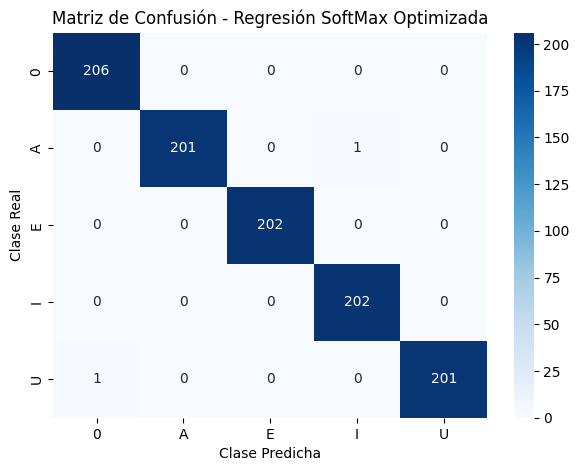

In [ ]:
print("--- Prueba y Evaluación Final (Conjunto de Prueba) ---")
# Predicción sobre el conjunto de prueba aislado
y_pred_softmax = mejor_modelo_softmax.predict(X_test_pca)
acc_test_softmax = accuracy_score(y_test, y_pred_softmax)

print(f"Exactitud en prueba: {acc_test_softmax:.2%}")
print(f"Errores en prueba: {np.count_nonzero(y_test != y_pred_softmax)} de {len(y_test)}")

# Definimos las clases explícitamente basados en tu dataset original
nombres_clases = ['0', 'A', 'E', 'I', 'U']

print(classification_report(
    y_test, y_pred_softmax, target_names=nombres_clases, digits=4
))
# Generar y graficar la matriz de confusión
cm_softmax = confusion_matrix(y_test, y_pred_softmax)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_softmax, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases,
            yticklabels=nombres_clases)
plt.title("Matriz de Confusión - Regresión SoftMax Optimizada")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show()


## Conclusión y análisis de resultados

**Selección de la representación.** Utilizando la misma configuración y las mismas cinco particiones de validación cruzada, Softmax con PCA alcanzó una exactitud media de **99,8521 %**, frente al **99,7781 %** obtenido sin PCA. La representación con PCA también presentó menor variación y redujo el tiempo medio de ajuste de 335,27 a 31,58 segundos. Por estas razones se conservaron los 94 componentes principales como entrada del modelo.

**Selección de la configuración.** Entre las 10 configuraciones evaluadas, `C = 100` con el optimizador `saga` obtuvo la mayor exactitud media en validación cruzada, con aproximadamente **99,90 %**. Este valor de `C` corresponde a la regularización más débil de la malla evaluada.

**Resultados en prueba.** El modelo clasificó correctamente **1.012 de las 1.014 imágenes**, alcanzando una exactitud de **99,80 %**. Confundió una imagen real de A con I y una imagen de U con la clase `0`. Reconoció correctamente todas las imágenes reales de las clases `0`, E e I.

**Alcance del resultado.** La proximidad entre la exactitud de validación cruzada y la exactitud de prueba evidencia un comportamiento estable en esta partición. No obstante, sería necesaria una evaluación externa para comprobar su desempeño con estilos de escritura diferentes a los incluidos en el dataset.

## Guardado del modelo Softmax

In [ ]:
print("\n--- Persistencia del Modelo ---")

ruta_softmax = RUTA_MODELOS / "mejor_modelo_softmax.pkl"
joblib.dump(mejor_modelo_softmax, ruta_softmax)

print(f"¡Modelo de Regresión SoftMax guardado exitosamente en: {ruta_softmax.name}!")


--- Persistencia del Modelo ---
¡Modelo de Regresión SoftMax guardado exitosamente en: mejor_modelo_softmax.pkl!


# Red neuronal profunda (DNN) con arquitectura convolucional (CNN)

La CNN clasifica cada imagen en una de las cinco clases del proyecto. Recibe imágenes de 32 × 32 píxeles en escala de grises y aplica filtros sobre regiones vecinas para aprender patrones locales, como bordes y trazos. En este modelo se conserva la disposición espacial de los píxeles, por lo que las imágenes se usan directamente sin aplicar PCA.

## Importación de bibliotecas y preparación de las imágenes

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
X_train_cnn = X_train.reshape(-1, 32, 32, 1).astype("float32")
X_test_cnn = X_test.reshape(-1, 32, 32, 1).astype("float32")

print("Entrenamiento:", X_train_cnn.shape)
print("Prueba:", X_test_cnn.shape)

Entrenamiento: (4056, 32, 32, 1)
Prueba: (1014, 32, 32, 1)


### Comprobación de la correspondencia de los datos

**Comprobación de la partición.** Se reorganizaron las 4.056 imágenes de entrenamiento y las 1.014 de prueba en cuadrículas de 32 × 32 píxeles con un canal. Para verificar que se mantuvieron las mismas imágenes y el mismo orden que en MLP y Softmax, se aplicó el PCA ya ajustado y se compararon los componentes resultantes con los que usaron esos modelos. Ambos conjuntos coincidieron dentro de la tolerancia numérica. La CNN se entrena con las cuadrículas de píxeles.

In [ ]:
for conjunto, imagenes, componentes in [
    ("Entrenamiento", X_train, X_train_pca),
    ("Prueba", X_test, X_test_pca),
]:
    coincide = np.allclose(
        pca.transform(imagenes), componentes, rtol=1e-4, atol=1e-4
    )
    assert coincide, f"Revisar la correspondencia de las imágenes de {conjunto.lower()}."
    print(f"{conjunto}: las imágenes coinciden con los datos transformados.")

Entrenamiento: las imágenes coinciden con los datos transformados.
Prueba: las imágenes coinciden con los datos transformados.


## Configuración de la red neuronal

La red recibe imágenes de 32 × 32 píxeles en escala de grises.
Usamos dos capas convolucionales con filtros de 3 × 3 para aprender
patrones locales, como bordes y curvas, y combinarlos en formas más complejas.
Usamos ReLU para que la red pueda aprender relaciones no lineales.

Después de cada convolución, MaxPooling de 2 × 2 reduce el tamaño
de los mapas de características. Así pasamos de 32 × 32 a 16 × 16
y luego a 8 × 8 antes de la capa densa, lo que reduce la cantidad
de parámetros de esa capa.

La salida tiene cinco neuronas, una por clase. Softmax convierte
sus puntajes en probabilidades. Usamos entropía cruzada para
clasificación multiclase porque cada imagen tiene una sola etiqueta.

La configuración inicial usa 16 filtros en la primera convolución
y 32 en la segunda. En la validación cruzada compararemos esta
configuración con 32 y 64 filtros para ver si aumentar la capacidad
mejora la exactitud. La capa densa de 32 neuronas se mantiene fija
para que la comparación se centre en la cantidad de filtros.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def construir_cnn(filtros=16):
    modelo = keras.Sequential([
        keras.Input(shape=(32, 32, 1)),
        layers.Conv2D(filtros, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(2 * filtros, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dense(len(label_encoder.classes_), activation="softmax"),
    ])

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    return modelo

print("Configuración de la red neuronal lista.")

Configuración de la red neuronal lista.


## Entrenamiento de la red neuronal

Comparamos dos configuraciones de filtros: 16 y 32, y 32 y 64.
Mantenemos fijas 10 épocas y lotes de 32 imágenes para que la
comparación se centre en el número de filtros. Las 10 épocas son
un presupuesto inicial que permite completar la búsqueda con
el mismo tiempo de entrenamiento en términos de pasadas por los datos.

Usamos GridSearchCV con cinco particiones estratificadas. Elegimos
la configuración con mayor exactitud media en validación y luego
la entrenamos con las 4.056 imágenes de entrenamiento. Las 1.014
imágenes de prueba se reservan para la evaluación final.

### Comparación de configuraciones de filtros

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin


class ClasificadorCNN(ClassifierMixin, BaseEstimator):
    def __init__(self, filtros=16, epochs=10, batch_size=32):
        self.filtros = filtros
        self.epochs = epochs
        self.batch_size = batch_size

    def fit(self, X, y):
        keras.backend.clear_session()
        keras.utils.set_random_seed(42)

        self.classes_, etiquetas = np.unique(y, return_inverse=True)
        self.modelo_ = construir_cnn(filtros=self.filtros)
        self.modelo_.fit(
            X,
            etiquetas,
            epochs=self.epochs,
            batch_size=self.batch_size,
            verbose=0,
        )
        return self

    def predict(self, X):
        probabilidades = self.modelo_.predict(X, verbose=0)
        return self.classes_[probabilidades.argmax(axis=1)]


grid_search_cnn = GridSearchCV(
    estimator=ClasificadorCNN(),
    param_grid={"filtros": [16, 32]},
    cv=StratifiedKFold(n_splits=5),
    scoring="accuracy",
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise",
)

grid_search_cnn.fit(X_train_cnn, y_train)

mejor_modelo_cnn = grid_search_cnn.best_estimator_.modelo_

filtros = grid_search_cnn.best_params_["filtros"]
print(f"Mejor configuración: {filtros} y {2 * filtros} filtros")
print(f"Exactitud media en validación: {grid_search_cnn.best_score_:.2%}")

Fitting 5 folds for each of 2 candidates, totalling 10 fits
[CV] END .........................................filtros=16; total time=  36.2s
[CV] END .........................................filtros=16; total time=  28.4s
[CV] END .........................................filtros=16; total time=  32.1s
[CV] END .........................................filtros=16; total time=  28.8s
[CV] END .........................................filtros=16; total time=  27.3s
[CV] END .........................................filtros=32; total time=  53.9s
[CV] END .........................................filtros=32; total time=  54.1s
[CV] END .........................................filtros=32; total time=  48.5s
[CV] END .........................................filtros=32; total time=  53.7s
[CV] END .........................................filtros=32; total time=  54.2s
Mejor configuración: 16 y 32 filtros
Exactitud media en validación: 100.00%


### Resultados de la comparación de filtros

In [ ]:
resultados_filtros_cnn = pd.DataFrame({
    "Filtros primera capa": [
        p["filtros"] for p in grid_search_cnn.cv_results_["params"]
    ],
    "Filtros segunda capa": [
        2 * p["filtros"] for p in grid_search_cnn.cv_results_["params"]
    ],
    "Exactitud media": grid_search_cnn.cv_results_["mean_test_score"],
    "Desviación estándar (pp)": (
        grid_search_cnn.cv_results_["std_test_score"] * 100
    ),
})

resultados_filtros_cnn = resultados_filtros_cnn.sort_values(
    "Exactitud media",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

display(
    resultados_filtros_cnn.style.format({
        "Exactitud media": "{:.4%}",
        "Desviación estándar (pp)": "{:.3f}",
    })
)

,Filtros primera capa,Filtros segunda capa,Exactitud media,Desviación estándar (pp)
0,16,32,100.0000%,0.000
1,32,64,100.0000%,0.000


### Comparación del número de épocas

In [ ]:
busqueda_cnn_epocas = GridSearchCV(
    estimator=ClasificadorCNN(
    filtros=grid_search_cnn.best_params_["filtros"],
    batch_size=32
),
    param_grid={"epochs": [10, 15, 20]},
    cv=StratifiedKFold(n_splits=5),
    scoring="accuracy",
    refit=False,
    n_jobs=1,
    verbose=1,
    error_score="raise",
)

busqueda_cnn_epocas.fit(X_train_cnn, y_train)

for parametros, media, desviacion in zip(
    busqueda_cnn_epocas.cv_results_["params"],
    busqueda_cnn_epocas.cv_results_["mean_test_score"],
    busqueda_cnn_epocas.cv_results_["std_test_score"],
):
    print(
        f"{parametros['epochs']} épocas: {media:.4%} "
        f"± {desviacion * 100:.3f} puntos porcentuales"
    )

Fitting 5 folds for each of 3 candidates, totalling 15 fits
10 épocas: 100.0000% ± 0.000 puntos porcentuales
15 épocas: 100.0000% ± 0.000 puntos porcentuales
20 épocas: 100.0000% ± 0.000 puntos porcentuales


### Selección de la configuración final

Las configuraciones de 10, 15 y 20 épocas alcanzaron una exactitud media del **100 %** en las cinco particiones de validación cruzada, con una desviación estándar de **0 puntos porcentuales**. Como aumentar el número de épocas no produjo una mejora, se seleccionaron **10 épocas** siguiendo un criterio de simplicidad y eficiencia computacional.

La configuración final utiliza **16 filtros en la primera capa convolucional, 32 filtros en la segunda, lotes de 32 imágenes, 10 épocas y el optimizador Adam con una tasa de aprendizaje de 0,001**. Esta es la configuración que se evaluará sobre el conjunto de prueba.

### Resumen de la arquitectura seleccionada

El siguiente resumen muestra las capas de la CNN, las dimensiones de salida y la cantidad de parámetros entrenables. Esto permite observar cómo las convoluciones y las operaciones de agrupamiento reducen progresivamente la representación espacial antes de realizar la clasificación final.

In [ ]:
mejor_modelo_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        65,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,601 (826.57 KB)

 Trainable params: 70,533 (275.52 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 141,068 (551.05 KB)

## Evaluación de la CNN en el conjunto de prueba

Evaluamos la CNN seleccionada sobre el mismo conjunto de prueba que
los demás métodos. Calculamos la exactitud, el F1 macro y el número
de errores. La matriz de confusión muestra qué clases confundió la red.

Exactitud en prueba: 99.90%
F1 macro: 99.90%
Errores: 1 de 1014

              precision    recall  f1-score   support

           0     0.9952    1.0000    0.9976       206
           A     1.0000    1.0000    1.0000       202
           E     1.0000    1.0000    1.0000       202
           I     1.0000    1.0000    1.0000       202
           U     1.0000    0.9950    0.9975       202

    accuracy                         0.9990      1014
   macro avg     0.9990    0.9990    0.9990      1014
weighted avg     0.9990    0.9990    0.9990      1014



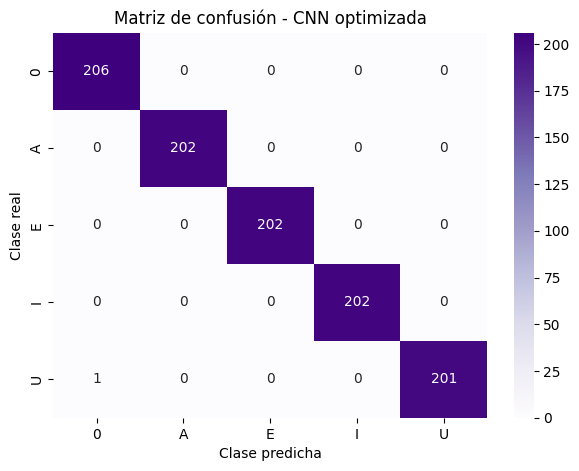

In [ ]:
from sklearn.metrics import f1_score

y_pred_cnn = grid_search_cnn.predict(X_test_cnn)
clases_cnn = label_encoder.classes_
etiquetas_cnn = np.arange(len(clases_cnn))

acc_test_cnn = accuracy_score(y_test, y_pred_cnn)
f1_macro_cnn = f1_score(y_test, y_pred_cnn, average="macro")
errores_cnn = np.count_nonzero(y_test != y_pred_cnn)

print(f"Exactitud en prueba: {acc_test_cnn:.2%}")
print(f"F1 macro: {f1_macro_cnn:.2%}")
print(f"Errores: {errores_cnn} de {len(y_test)}")
print()
print(classification_report(
    y_test, y_pred_cnn, labels=etiquetas_cnn, target_names=clases_cnn,
    digits=4, zero_division=0,
))

cm_cnn = confusion_matrix(y_test, y_pred_cnn, labels=etiquetas_cnn)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_cnn, annot=True, fmt="d", cmap="Purples",
    xticklabels=clases_cnn, yticklabels=clases_cnn,
)
plt.title("Matriz de confusión - CNN optimizada")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.show()

## Conclusión y análisis de resultados

**Selección de la arquitectura.** La CNN recibió imágenes de 32 × 32 píxeles en escala de grises, conservando la disposición espacial de los píxeles. Mediante validación cruzada estratificada de cinco particiones se compararon dos arquitecturas: una con 16 y 32 filtros, y otra con 32 y 64 filtros. Ambas alcanzaron una exactitud media del **100 %**, con una desviación estándar de **0 puntos porcentuales**. Debido a que no se observó una mejora al aumentar la cantidad de filtros, se seleccionó la arquitectura de **16 y 32 filtros** por requerir menos parámetros y menor costo computacional.

**Selección del número de épocas.** Con la arquitectura seleccionada se compararon entrenamientos de 10, 15 y 20 épocas. Las tres alternativas obtuvieron una exactitud media del **100 %** y una desviación estándar de **0 puntos porcentuales**. Se seleccionaron **10 épocas**, ya que aumentar el número de pasadas sobre los datos no produjo una mejora en la validación cruzada.

**Rendimiento en el conjunto de prueba.** La configuración final clasificó correctamente **1.013 de las 1.014 imágenes**, con una exactitud de **99,90 %** y un F1 macro de **99,90 %**. Reconoció correctamente todas las imágenes reales de las clases `0`, A, E e I. En la clase U acertó **201 de 202 imágenes** y el único error consistió en clasificar una U como `0`.

**Interpretación del resultado.** La diferencia entre el 100 % obtenido en validación cruzada y el 99,90 % alcanzado en prueba corresponde a una sola imagen. Los resultados muestran que la CNN aprendió adecuadamente los patrones espaciales de las vocales mediante sus capas convolucionales. No obstante, el desempeño corresponde al conjunto de datos utilizado y debe comprobarse posteriormente con imágenes de otros autores, estilos de escritura y condiciones de captura.

## Guardado del modelo CNN

La arquitectura y los pesos de la CNN seleccionada se guardan en formato `.keras`. Este archivo permite recuperar el modelo para realizar nuevas predicciones sin repetir la búsqueda de hiperparámetros ni el entrenamiento.

In [ ]:
print("\n--- Guardado del modelo CNN ---")

ruta_cnn = RUTA_MODELOS / "cnn_model.keras"
mejor_modelo_cnn.save(ruta_cnn)

print(f"Modelo CNN guardado correctamente en: {ruta_cnn.name}")


--- Guardado del modelo CNN ---
Modelo CNN guardado correctamente en: cnn_model.keras


# Comparación final de los modelos

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

predicciones = {
    "Random Forest": pred_rf_final_test,
    "Árbol de decisión": y_pred_dt_sin_pca,
    "Perceptrón multicapa (MLP)": y_pred_mlp,
    "Regresión logística multiclase (Softmax)": y_pred_softmax,
    "Red neuronal convolucional (CNN)": y_pred_cnn,
}

etiquetas_prueba = np.asarray(y_test).ravel()
resultados_finales = []

for nombre, prediccion in predicciones.items():
    etiquetas_predichas = np.asarray(prediccion).ravel()

    if len(etiquetas_predichas) != len(etiquetas_prueba):
        raise ValueError(
            f"{nombre} no contiene el mismo número de predicciones que y_test."
        )

    resultados_finales.append({
        "Modelo": nombre,
        "Exactitud": accuracy_score(
            etiquetas_prueba,
            etiquetas_predichas,
        ),
        "F1 macro": f1_score(
            etiquetas_prueba,
            etiquetas_predichas,
            average="macro",
            zero_division=0,
        ),
        "Errores": np.count_nonzero(
            etiquetas_prueba != etiquetas_predichas
        ),
    })

tabla_comparacion_final = (
    pd.DataFrame(resultados_finales)
    .sort_values(
        ["Exactitud", "F1 macro"],
        ascending=False,
        kind="stable",
    )
    .reset_index(drop=True)
)

display(
    tabla_comparacion_final.style.format({
        "Exactitud": "{:.2%}",
        "F1 macro": "{:.2%}",
    }).hide(axis="index")
)

Modelo,Exactitud,F1 macro,Errores
Red neuronal convolucional (CNN),99.90%,99.90%,1
Regresión logística multiclase (Softmax),99.80%,99.80%,2
Perceptrón multicapa (MLP),99.70%,99.70%,3
Random Forest,99.61%,99.61%,4
Árbol de decisión,96.25%,96.27%,38


## Comparación de métricas en el conjunto de prueba

Se comparan la exactitud, la precisión macro, la sensibilidad macro y el F1 macro de los cinco modelos sobre las mismas 1.014 imágenes de prueba. Las métricas macro asignan el mismo peso a cada vocal, por lo que permiten comprobar que el buen resultado global no depende solamente de una clase.

El eje vertical se amplía desde el 94 % para hacer visibles las pequeñas diferencias entre modelos.

Modelo,Exactitud,Precisión macro,Sensibilidad macro,F1 macro
Red neuronal convolucional (CNN),99.90%,99.90%,99.90%,99.90%
Regresión logística multiclase (Softmax),99.80%,99.80%,99.80%,99.80%
Perceptrón multicapa (MLP),99.70%,99.71%,99.70%,99.70%
Random Forest,99.61%,99.61%,99.61%,99.61%
Árbol de decisión,96.25%,96.31%,96.25%,96.27%


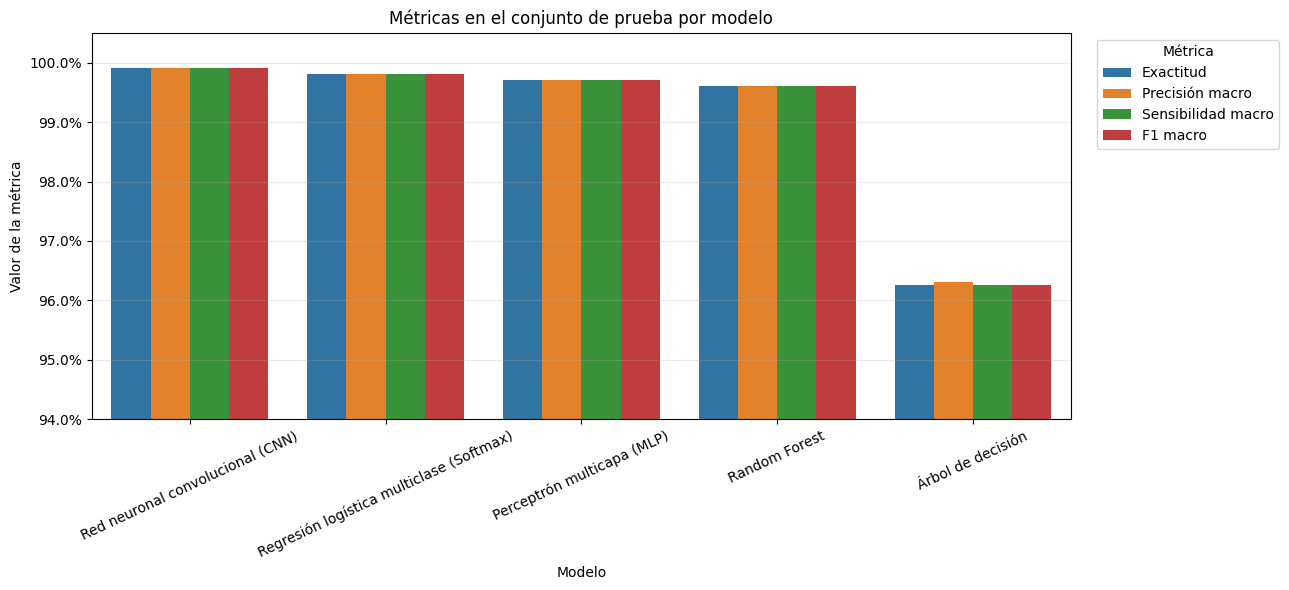

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from matplotlib.ticker import PercentFormatter

filas_metricas = []

for modelo, prediccion in predicciones.items():
    y_pred = np.asarray(prediccion).ravel()

    filas_metricas.append({
        "Modelo": modelo,
        "Exactitud": accuracy_score(etiquetas_prueba, y_pred),
        "Precisión macro": precision_score(
            etiquetas_prueba, y_pred,
            average="macro",
            zero_division=0,
        ),
        "Sensibilidad macro": recall_score(
            etiquetas_prueba, y_pred,
            average="macro",
            zero_division=0,
        ),
        "F1 macro": f1_score(
            etiquetas_prueba, y_pred,
            average="macro",
            zero_division=0,
        ),
    })

tabla_metricas_final = pd.DataFrame(filas_metricas)
tabla_metricas_final = (
    tabla_metricas_final
    .set_index("Modelo")
    .loc[tabla_comparacion_final["Modelo"]]
    .reset_index()
)

display(
    tabla_metricas_final.style.format({
        "Exactitud": "{:.2%}",
        "Precisión macro": "{:.2%}",
        "Sensibilidad macro": "{:.2%}",
        "F1 macro": "{:.2%}",
    }).hide(axis="index")
)

metricas_largas = tabla_metricas_final.melt(
    id_vars="Modelo",
    var_name="Métrica",
    value_name="Valor",
)

orden_modelos = tabla_comparacion_final["Modelo"].tolist()

fig, ax = plt.subplots(figsize=(13, 6))

sns.barplot(
    data=metricas_largas,
    x="Modelo",
    y="Valor",
    hue="Métrica",
    order=orden_modelos,
    ax=ax,
)

ax.set_title("Métricas en el conjunto de prueba por modelo")
ax.set_xlabel("Modelo")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0.94, 1.005)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Métrica", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

## Comparación de la exactitud en entrenamiento y prueba

Esta gráfica permite analizar la capacidad de generalización de los modelos. Una diferencia considerable entre la exactitud de entrenamiento y la de prueba puede indicar sobreajuste. Todos los modelos se comparan utilizando la misma partición previamente definida.

Modelo,Entrenamiento,Prueba
Red neuronal convolucional (CNN),100.00%,99.90%
Regresión logística multiclase (Softmax),100.00%,99.80%
Perceptrón multicapa (MLP),100.00%,99.70%
Random Forest,100.00%,99.61%
Árbol de decisión,99.83%,96.25%


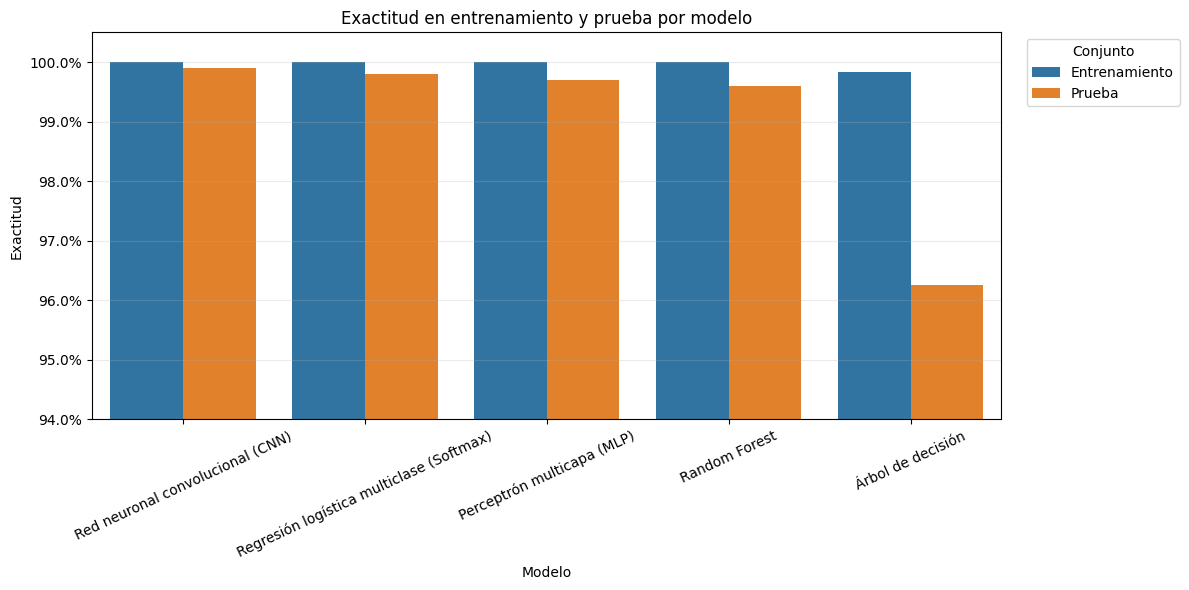

In [ ]:
from sklearn.metrics import accuracy_score
from matplotlib.ticker import PercentFormatter

predicciones_entrenamiento = {
    "Random Forest": modelo_rf_final.predict(X_train),
    "Árbol de decisión": modelo_dt_sin_pca.predict(X_train),
    "Perceptrón multicapa (MLP)": mejor_modelo_mlp.predict(X_train_pca),
    "Regresión logística multiclase (Softmax)": mejor_modelo_softmax.predict(
        X_train_pca
    ),
    "Red neuronal convolucional (CNN)": grid_search_cnn.predict(
        X_train_cnn
    ),
}

exactitud_entrenamiento = {
    modelo: accuracy_score(y_train, prediccion)
    for modelo, prediccion in predicciones_entrenamiento.items()
}

exactitud_prueba = dict(zip(
    tabla_comparacion_final["Modelo"],
    tabla_comparacion_final["Exactitud"],
))

tabla_train_test = pd.DataFrame({
    "Modelo": tabla_comparacion_final["Modelo"],
    "Entrenamiento": [
        exactitud_entrenamiento[modelo]
        for modelo in tabla_comparacion_final["Modelo"]
    ],
    "Prueba": [
        exactitud_prueba[modelo]
        for modelo in tabla_comparacion_final["Modelo"]
    ],
})

display(
    tabla_train_test.style.format({
        "Entrenamiento": "{:.2%}",
        "Prueba": "{:.2%}",
    }).hide(axis="index")
)

comparacion_train_test = tabla_train_test.melt(
    id_vars="Modelo",
    var_name="Conjunto",
    value_name="Exactitud",
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=comparacion_train_test,
    x="Modelo",
    y="Exactitud",
    hue="Conjunto",
    ax=ax,
)

ax.set_title("Exactitud en entrenamiento y prueba por modelo")
ax.set_xlabel("Modelo")
ax.set_ylabel("Exactitud")
ax.set_ylim(0.94, 1.005)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend(
    title="Conjunto",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

## Comparación del número de errores

Debido a que varios modelos alcanzaron exactitudes cercanas al 100 %, se compara también el número absoluto de clasificaciones incorrectas sobre las 1.014 imágenes de prueba. Esta representación permite observar con mayor claridad diferencias que parecen pequeñas cuando se expresan solamente mediante porcentajes.

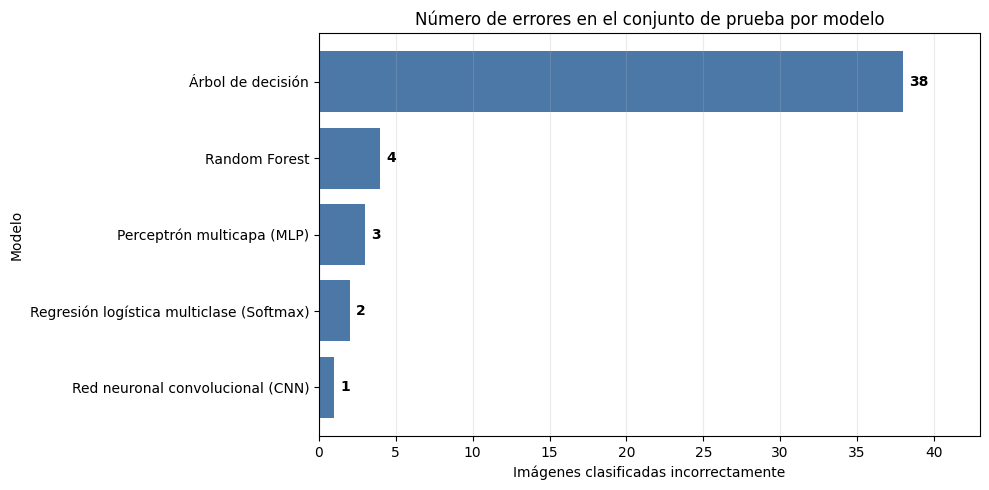

In [ ]:

import matplotlib.pyplot as plt
tabla_errores = (
    tabla_comparacion_final
    .sort_values("Errores", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    tabla_errores["Modelo"],
    tabla_errores["Errores"],
    color="#4C78A8",
)

for barra, errores in zip(barras, tabla_errores["Errores"]):
    ax.text(
        errores + 0.4,
        barra.get_y() + barra.get_height() / 2,
        str(errores),
        va="center",
        fontweight="bold",
    )

ax.set_title("Número de errores en el conjunto de prueba por modelo")
ax.set_xlabel("Imágenes clasificadas incorrectamente")
ax.set_ylabel("Modelo")
ax.set_xlim(0, tabla_errores["Errores"].max() + 5)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## Conclusión de la comparación


### Resultados del proyecto

Los cinco modelos se evaluaron sobre el mismo conjunto de prueba aislado de 1.014 imágenes, después de seleccionar sus configuraciones mediante validación cruzada utilizando únicamente los datos de entrenamiento.

La red neuronal convolucional (CNN) obtuvo el mejor desempeño, con una exactitud y un F1 macro del **99,90 %**, equivalentes a **1.013 clasificaciones correctas y un solo error**. Softmax alcanzó **99,80 %** y dos errores; el MLP, **99,70 %** y tres errores; Random Forest, **99,61 %** y cuatro errores; y el árbol de decisión, **96,25 %** y 38 errores.

La CNN también alcanzó una exactitud media del **100 % en validación cruzada**. Como las configuraciones evaluadas empataron, se seleccionó la arquitectura más sencilla, con 16 y 32 filtros y 10 épocas. Su resultado en prueba confirmó su capacidad de generalización, por lo que se propone como modelo final del proyecto.

### Lecciones aprendidas

La representación adecuada depende del tipo de modelo. PCA se conservó para Random Forest, MLP y Softmax, reduciendo las 1.024 características originales a 94 componentes. Para el árbol se seleccionaron los píxeles sin PCA, mientras que la CNN utilizó directamente las imágenes de 32 × 32 píxeles para conservar su estructura espacial.

El árbol de decisión presentó el indicio más claro de sobreajuste: pasó de aproximadamente **99,83 % en entrenamiento a 96,25 % en prueba**, una reducción cercana a **3,57 puntos porcentuales**. Esto demuestra que un resultado elevado en entrenamiento no garantiza el mismo desempeño con datos no vistos.

Los resultados también muestran la importancia de separar los datos de prueba y utilizarlos únicamente para la evaluación final, después de seleccionar las configuraciones mediante validación cruzada.

### Trabajo futuro

Para comprobar y mejorar la capacidad de generalización del sistema se propone:

- Evaluar el modelo con imágenes escritas por personas no incluidas en el conjunto original.
- Incorporar distintos estilos de escritura y condiciones reales de captura.
- Aplicar aumento de datos mediante pequeñas rotaciones, desplazamientos y variaciones de contraste.
- Analizar la confianza de las predicciones y establecer un criterio para detectar casos inciertos.
- Estudiar con mayor detalle la confusión entre `0`, que representa la vocal O, y la vocal U.

### Consideraciones éticas

Tomando como referencia la **Recomendación sobre la Ética de la Inteligencia Artificial de la UNESCO (2021)**, una aplicación real de este sistema de reconocimiento de vocales debería considerar los siguientes aspectos:

1. **Privacidad y consentimiento.** Las imágenes de escritura pueden contener características particulares de una persona. Su recolección debe realizarse con autorización, informar el propósito del tratamiento y evitar conservar información personal innecesaria.

2. **Seguridad de la información.** El conjunto de datos y las predicciones deben almacenarse de forma segura. El acceso a las imágenes debe limitarse para evitar su filtración, modificación o utilización con fines distintos a los autorizados.

3. **Equidad y no discriminación.** El modelo fue entrenado con un conjunto específico y podría disminuir su rendimiento frente a estilos de escritura, edades, condiciones motrices o formas de captura que no estén suficientemente representadas. Antes de utilizarlo en un entorno real debe evaluarse con una población más diversa.

4. **Transparencia.** Los usuarios deben saber que la clasificación fue realizada mediante inteligencia artificial, conocer sus limitaciones y comprender que la etiqueta `0` se utiliza en este proyecto para representar la vocal O.

5. **Supervisión humana.** Una exactitud del 99,90 % no significa que el sistema sea infalible. En contextos educativos, administrativos o de accesibilidad, los casos inciertos deben ser revisados por una persona y el usuario debe poder solicitar una corrección.

6. **Responsabilidad.** Debe existir un responsable del funcionamiento del sistema, de la atención de errores y de la actualización del modelo cuando se detecten fallos o grupos de usuarios con menor desempeño.

7. **Uso proporcional.** El sistema debe emplearse únicamente como apoyo para reconocer vocales. No debe utilizarse para evaluar capacidades cognitivas, diagnosticar dificultades de aprendizaje ni tomar decisiones sobre una persona sin evidencia adicional y valoración profesional.

En consecuencia, el buen desempeño obtenido en este conjunto de prueba no es suficiente para justificar un despliegue inmediato. Antes de una aplicación real se necesitan evaluaciones externas, protección de los datos, supervisión humana y mecanismos claros para corregir decisiones equivocadas.